# Exploratory Data Analysis (EDA)

## 1. Pravidla práce

- EDA není jen generování grafů, ale systematické porozumění datům.
- Každý krok analýzy by měl mít vazbu na cíl projektu, KPI nebo analytickou otázku.
- Nestačí ukázat výstup; je potřeba stručně interpretovat, co z něj plyne a co z něj naopak tvrdit nelze.
- Pokud data obsahují problém, omezení nebo nekonzistenci, uveďte to explicitně.
- AI používejte jako pomocníka pro návrh postupu, struktury a kódu, ne jako zdroj hotových závěrů.
- Všechny závěry musí být dohledatelné a ověřitelné přímo z dat a kroků v notebooku.
- Pokud něco nelze zjistit spolehlivě, napište to otevřeně a nepřehánějte interpretaci.

> **Důležité**
> Pošte komentáře k datům, k výstupům.
> Celý výstup by měl sloužit jako prezentace někomu jinému.

## 2. Kontext analýzy
> **Účel:**  
> Ukotvit analýzu v semestrálním projektu a vyjasnit, proč jsou tato data a tato EDA relevantní.

> **Důležité:**  
> Tato sekce má být stručná a věcná. Nejde o obecný popis projektu, ale o vysvětlení, jak tato analýza souvisí s cílem projektu, otázkami a KPI.

- **Název projektu:** Formula Engineering
- **Stručný popis projektu / domény:** Sportovní analýza pro menší týmy
- **Cíl této analýzy:** porozumění datům, kontrola správnosti a smyslu dat
- **Hlavní analytické otázky:**
    1. Jak si stojíme v rychlosti zastávek v boxech oproti absolutní špičce a ztrácíme tím čas?
    2. Kdy je optimální okno pro výměnu pneumatik (pit window), abychom minimalizovali časovou ztrátu z degradace?
    3. Jsou naše investice do vývoje vozu efektivní v porovnání s konkurencí z hlediska získaných bodů?
  

- **KPI nebo metriky, ke kterým se EDA vztahuje:**
  1. Degradation Delta; Vypočítá degradaci každého kola oproti průměru prvních 3 'ostrých' kol na dané sadě pneumatik.
  2. PIT Stop Efficiency Index; porovnává časy PIT stopů s ostatními piloty
  3. ROI: kolik bodů tým získal vzhledem k nákladům na vývoj v daném závodě


## 3. Načtení dat a technická příprava
> **Účel:**  
> Zajistit nastavení notebooku a načtení dat pro další analýzu.

> **Zde udělejte například:**  
> - import potřebných knihoven  
> - připojení k DuckDB  
> - načtení nebo vytvoření relevantních tabulek / pohledů  
>   - integrace dat do db
> - základní nastavení prostředí notebooku  
> - první kontrolu, že data jsou dostupná a načtená správně

In [ ]:
# --- Importy a kontrola prostředí ---
import importlib.util
import subprocess
import sys
from pathlib import Path

def ensure_package(package_name: str, import_name: str | None = None) -> None:
    """Zkontroluje přítomnost balíčku a případně jej doinstaluje."""
    module_name = import_name or package_name
    if importlib.util.find_spec(module_name) is None:
        print(f"Balíček '{package_name}' není nainstalovaný. Probíhá instalace...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package_name])
    else:
        print(f"Balíček '{package_name}' je dostupný.")

# Upravte seznam balíčků podle potřeby projektu
ensure_package("duckdb")
ensure_package("pandas")
ensure_package("matplotlib")
ensure_package("jupyter")  # volitelné, pokud běžíte notebook lokálně

import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import random
import os
import requests
import time
import json
import glob
from IPython.display import display, HTML
import seaborn as sns


# Volitelné nastavení zobrazení
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 140)

# --- Připojení k DuckDB ---
DB_PATH = "projekt.duckdb"  # upravte podle svého projektu
con = duckdb.connect(DB_PATH)

print(f"Připojeno k databázi: {Path(DB_PATH).resolve()}")

# --- Příklad integrace dat do DuckDB ---
# Nahraďte cestami a názvy tabulek podle vlastního projektu.
# con.execute("CREATE OR REPLACE TABLE events AS SELECT * FROM read_csv_auto('data/events.csv')")
# con.execute("CREATE OR REPLACE TABLE users AS SELECT * FROM read_parquet('data/users.parquet')")

# --- První kontrola přítomnosti tabulek ---
try:
    tables_df = con.execute("SHOW TABLES").df()
    display(tables_df)
except Exception as e:
    print("Nepodařilo se vypsat tabulky. Zkontrolujte načtení dat a připojení k DB.")
    print(e)

Balíček 'duckdb' je dostupný.
Balíček 'pandas' je dostupný.
Balíček 'matplotlib' je dostupný.
Balíček 'jupyter' je dostupný.
Připojeno k databázi: /content/projekt.duckdb


,name


In [ ]:

# vytvoření složky pro data na GDrive
from google.colab import drive
drive.mount('/content/drive')

# incicializace


PROJECT_FOLDER = '/content/drive/MyDrive/F1-Projekt'
if not os.path.exists(PROJECT_FOLDER):
    os.makedirs(PROJECT_FOLDER)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# inicializace databáze

# Define the path for the persistent DuckDB database file
db_file_path = os.path.join(PROJECT_FOLDER, 'f1_database.duckdb')

# Check if the database file already exists
db_exists = os.path.exists(db_file_path)

# Initialize DuckDB - connect to a persistent database file
con = duckdb.connect(database=db_file_path)

# Print a message indicating whether a new database was created or an existing one was connected to
if db_exists:
    print(f"DuckDB connected to existing persistent database file: {db_file_path}")
else:
    print(f"DuckDB initialized and created new persistent database file: {db_file_path}")

DuckDB connected to existing persistent database file: /content/drive/MyDrive/F1-Projekt/f1_database.duckdb


### 3.1. Stahování dat

In [ ]:
# ==========================================
# KONFIGURACE PIPELINE
# ==========================================
#SESSION_KEY = 11234
SESSION_KEY = 11253
BASE_URL = "https://api.openf1.org/v1/"

# Původně: OUTPUT_DIR = "openf1_raw_data"
# Nyní bude ukládáno na Google Drive do složky projektu
OUTPUT_DIR = os.path.join(PROJECT_FOLDER, "openf1_raw_data")

# Nastavení chování k API (Free tier ochrana)
DELAY_GENERAL = 2       # Pauza mezi lehkými endpointy (sekundy)
DELAY_TELEMETRY = 3     # Pauza mezi objemnou telemetrií (sekundy)
TIMEOUT_GENERAL = 15    # Timeout pro lehké endpointy (sekundy)
TIMEOUT_TELEMETRY = 45  # Timeout pro objemnou telemetrii (sekundy)

# Seznam základních endpointů (bez car_data a location)
GENERAL_ENDPOINTS = [
    "sessions",
    "laps",
    "pit",
    "weather",
    "stints",
    "intervals",
    "race_control",
    "position"
]

# ==========================================
# POMOCNÉ FUNKCE
# ==========================================
def get_drivers_for_session(session_key):
    """Získá unikátní seznam čísel jezdců pro danou session."""
    url = f"{BASE_URL}drivers?session_key={session_key}"
    print(f"🔍 Získávám seznam jezdců pro session {session_key}...")

    try:
        response = requests.get(url, timeout=TIMEOUT_GENERAL)
        response.raise_for_status()
        drivers_data = response.json()

        driver_numbers = list(set([driver['driver_number'] for driver in drivers_data]))
        print(f"✅ Nalezeno {len(driver_numbers)} jezdců: {driver_numbers}\n")
        return driver_numbers

    except Exception as e:
        print(f"❌ Nelze načíst seznam jezdců: {e}\n")
        return []

# ==========================================
# HLAVNÍ WORKERY
# ==========================================
def download_general_data():
    """Stáhne základní data o session (časy, pneu, počasí...)."""
    print("🚀 FÁZE 1: Stahování základních dat o session...")

    for endpoint in GENERAL_ENDPOINTS:
        url = f"{BASE_URL}{endpoint}?session_key={SESSION_KEY}"
        filename = os.path.join(OUTPUT_DIR, f"{endpoint}_{SESSION_KEY}.json")

        if os.path.exists(filename):
          print(f"   ⏭️ Přeskakuji: {endpoint} (soubor již existuje)")
          continue

        print(f"   Stahuji: {endpoint}...")
        try:
            response = requests.get(url, timeout=TIMEOUT_GENERAL)
            response.raise_for_status()
            data = response.json()

            with open(filename, 'w', encoding='utf-8') as f:
                json.dump(data, f, indent=4)

            print(f"   ✅ Uloženo {len(data)} záznamů.")
        except Exception as e:
            print(f"   ❌ Chyba u {endpoint}: {e}")

        time.sleep(DELAY_GENERAL)
    print("🏁 Fáze 1 dokončena.\n")

def download_telemetry_data():
    """Stáhne vysokofrekvenční telemetrii (car_data) pro každého jezdce."""
    print("🚀 FÁZE 2: Stahování telemetrie (car_data) po jezdcích...")

    drivers = get_drivers_for_session(SESSION_KEY)
    if not drivers:
        print("   ⚠️ Přeskakuji Fázi 2 (nejsou k dispozici jezdci).")
        return

    for driver_no in drivers:
        url = f"{BASE_URL}car_data?session_key={SESSION_KEY}&driver_number={driver_no}"
        filename = os.path.join(OUTPUT_DIR, f"car_data_{SESSION_KEY}_driver_{driver_no}.json")

        if os.path.exists(filename):
          print(f"   ⏭️ Přeskakuji: car_data pro jezdce č. {driver_no} (soubor již existuje)")
          continue

        print(f"   Stahuji telemetrii pro jezdce č. {driver_no}...")
        try:
            response = requests.get(url, timeout=TIMEOUT_TELEMETRY)
            response.raise_for_status()
            data = response.json()

            # Záměrně bez indent=4 pro úsporu místa na disku u velkých dat
            with open(filename, 'w', encoding='utf-8') as f:
                json.dump(data, f)

            print(f"   ✅ Uloženo {len(data)} záznamů.")
        except requests.exceptions.Timeout:
            print(f"   ⏱️ ❌ Timeout ({TIMEOUT_TELEMETRY}s)!")
        except Exception as e:
            print(f"   ❌ Chyba: {e}")

        time.sleep(DELAY_TELEMETRY)
    print("🏁 Fáze 2 dokončena.\n")

# ==========================================
# SPUŠTĚNÍ
# ==========================================
if __name__ == "__main__":
    # Vytvoření složky, pokud neexistuje
    if not os.path.exists(OUTPUT_DIR):
        os.makedirs(OUTPUT_DIR)
        print(f"📁 Vytvořena složka: {OUTPUT_DIR}\n")

    print(f"=== ZAHÁJENÍ EXTRAKCE DAT (Session: {SESSION_KEY}) ===\n")
    download_general_data()
    download_telemetry_data()
    print("=== VŠECHNA DATA BYLA ÚSPĚŠNĚ STAŽENA ===")

=== ZAHÁJENÍ EXTRAKCE DAT (Session: 11253) ===

🚀 FÁZE 1: Stahování základních dat o session...
   ⏭️ Přeskakuji: sessions (soubor již existuje)
   ⏭️ Přeskakuji: laps (soubor již existuje)
   ⏭️ Přeskakuji: pit (soubor již existuje)
   ⏭️ Přeskakuji: weather (soubor již existuje)
   ⏭️ Přeskakuji: stints (soubor již existuje)
   ⏭️ Přeskakuji: intervals (soubor již existuje)
   ⏭️ Přeskakuji: race_control (soubor již existuje)
   ⏭️ Přeskakuji: position (soubor již existuje)
🏁 Fáze 1 dokončena.

🚀 FÁZE 2: Stahování telemetrie (car_data) po jezdcích...
🔍 Získávám seznam jezdců pro session 11253...
✅ Nalezeno 22 jezdců: [1, 3, 5, 6, 10, 11, 12, 14, 16, 18, 23, 27, 30, 31, 41, 43, 44, 55, 63, 77, 81, 87]

   ⏭️ Přeskakuji: car_data pro jezdce č. 1 (soubor již existuje)
   ⏭️ Přeskakuji: car_data pro jezdce č. 3 (soubor již existuje)
   ⏭️ Přeskakuji: car_data pro jezdce č. 5 (soubor již existuje)
   ⏭️ Přeskakuji: car_data pro jezdce č. 6 (soubor již existuje)
   ⏭️ Přeskakuji: car_data 

## 3.2. Generování syntetických dat dat

In [ ]:

# Konfigurace
# SESSION_KEY = 11234
SESSION_KEY = 11253

# Původně: OUTPUT_DIR = "openf1_raw_data"
# Nyní bude ukládáno na Google Drive do složky projektu
OUTPUT_DIR = os.path.join(PROJECT_FOLDER, "openf1_synthetic_data")
RAW_DATA_DIR = os.path.join(PROJECT_FOLDER, "openf1_raw_data")

NUM_LAPS = 53
RACE_NUMBER = 3

# Fiktivní data o týmech a jezdcích (seřazení na zákldě dosavadních výsledků sézóny 2026 :( )
TEAMS = {
    "Mercedes": {"drivers": [12, 63], "tier": "Top"},
    "Ferrari": {"drivers": [16, 44], "tier": "Top"},
    "McLaren": {"drivers": [1, 81], "tier": "Top"},
    "Haas F1 Team": {"drivers": [31, 87], "tier": "Mid"},
    "Red Bull Racing": {"drivers": [3, 6], "tier": "Top"},
    "Racing Bulls": {"drivers": [30, 41], "tier": "Mid"},
    "Alpine": {"drivers": [10, 43], "tier": "Back"},
    "Audi": {"drivers": [27, 5], "tier": "Mid"},
    "Williams": {"drivers": [55, 23], "tier": "Back"},
    "Cadillac": {"drivers": [11, 77], "tier": "Back"},
    "Aston Martin": {"drivers": [14, 18], "tier": "Back"},
}

def generate_synthetic_lap_data():
    """
    Generuje syntetická data pro spotřebu paliva na každé kolo.
    Dříve zde bylo i opotřebení motoru, ale to nyní nahrazujeme jinou metrikou.
    """
    print("Generuji syntetickou telemetrii (palivo) na úroveň kol...")
    data = []

    # Simulace vývoje teploty trati během závodu (např. odpoledne chladne)
    # Začínáme na 35°C a postupně klesáme, přidáváme náhodný šum
    base_temps = np.linspace(35.0, 28.0, NUM_LAPS) + np.random.normal(0, 1.5, NUM_LAPS)

    for team, info in TEAMS.items():
        for driver_no in info["drivers"]:
            for lap in range(1, NUM_LAPS + 1):
                track_temp = base_temps[lap - 1]

                # Spotřeba paliva (kg/kolo)
                # Základní spotřeba je cca 1.6 kg/kolo.
                # Korelace: Vyšší teplota zvyšuje spotřebu + náhodný šum senzoru
                temp_impact_fuel = (track_temp - 30) * 0.015
                noise_fuel = np.random.normal(0, 0.05)
                fuel_consumed = 1.6 + temp_impact_fuel + noise_fuel

                data.append({
                    "session_key": SESSION_KEY,
                    "driver_number": driver_no,
                    "lap_number": lap,
                    "track_temperature_C": round(track_temp, 2),
                    "fuel_consumed_kg": round(max(1.0, fuel_consumed), 3),
                })

    return pd.DataFrame(data)

def generate_team_costs():
    """
    Generuje syntetická data o nákladech na vývoj (R&D) v daném závodním víkendu.
    Slouží pro výpočet ROI.
    """
    print("Generuji syntetická data o nákladech (R&D) pro výpočet ROI...")
    data = []

    for team, info in TEAMS.items():
        # Základní investice podle úrovně týmu
        if info["tier"] == "Top":
            base_cost = 2_500_000
        elif info["tier"] == "Mid":
            base_cost = 1_200_000
        else:
            base_cost = 500_000

        # Přidání šumu (některý závod přivezou více vylepšení, jiný méně)
        # Šum je v rozmezí +/- 20%
        noise_factor = np.random.uniform(0.8, 1.2)
        actual_cost = int(base_cost * noise_factor)

        data.append({
            "session_key": SESSION_KEY,
            "team_name": team,
            "development_cost_usd": actual_cost
        })

    return pd.DataFrame(data)

def generate_crash_damage_costs(session_key, raw_data_dir, num_laps_race, teams_dict):
    """
    Generuje syntetické náklady na poškození pro jezdce na základě reálných dat (DNF, dlouhé pit stopy).
    """
    print("Generuji syntetická data o nákladech na poškození (Crash Damage Costs)...")
    crash_costs_data = []

    # Načtení dat o kolech a pit stopech z JSON souborů
    laps_file = os.path.join(raw_data_dir, f"laps_{session_key}.json")
    pit_file = os.path.join(raw_data_dir, f"pit_{session_key}.json")

    laps_raw = []
    if os.path.exists(laps_file):
        with open(laps_file, 'r', encoding='utf-8') as f:
            laps_raw = json.load(f)
    df_laps_raw = pd.DataFrame(laps_raw)

    pit_raw = []
    if os.path.exists(pit_file):
        with open(pit_file, 'r', encoding='utf-8') as f:
            pit_raw = json.load(f)
    df_pit_raw = pd.DataFrame(pit_raw)

    # Identifikace jezdců s DNF (Did Not Finish) - nedokončili všechna kola
    dnf_drivers = set()
    if not df_laps_raw.empty:
        max_laps_per_driver = df_laps_raw.groupby('driver_number')['lap_number'].max()
        # Zde předpokládáme, že NUM_LAPS je max. počet kol závodu
        for driver_no, max_lap in max_laps_per_driver.items():
            if max_lap < num_laps_race:
                dnf_drivers.add(driver_no)

    # Identifikace jezdců s velmi dlouhými pit stopy (indikace poškození)
    long_pit_stop_drivers = set()
    if not df_pit_raw.empty:
        # Vyfiltrujeme pit stopy delší než 25 sekund jako indikaci možného poškození
        long_pit_stops = df_pit_raw[df_pit_raw['pit_duration'] > 25]
        long_pit_stop_drivers.update(long_pit_stops['driver_number'].unique())

    # Kombinace incidentů a přiřazení nákladů
    for team, info in teams_dict.items():
        for driver_no in info["drivers"]:
            cost = 0
            if driver_no in dnf_drivers or driver_no in long_pit_stop_drivers:
                # Generujeme náhodnou částku mezi 150 000 a 2 000 000 USD
                cost = random.randint(150_000, 2_000_000)
            # else:
            #     # Pro jezdce bez incidentů (nebo velmi malé náklady)
            #     cost = random.randint(0, 5000) # Malé nominální náklady

            crash_costs_data.append({
                "session_key": session_key,
                "driver_number": driver_no,
                "crash_damage_costs_usd": cost
            })

    return pd.DataFrame(crash_costs_data)


if __name__ == "__main__":
    # Vytvoření složky, pokud neexistuje
    if not os.path.exists(OUTPUT_DIR):
        os.makedirs(OUTPUT_DIR)

    # Generování dat
    df_synthetic_lap_data = generate_synthetic_lap_data()
    df_costs = generate_team_costs()
    df_crash_costs = generate_crash_damage_costs(SESSION_KEY, RAW_DATA_DIR, NUM_LAPS, TEAMS)

    # Uložení do CSV
    synthetic_lap_data_path = os.path.join(OUTPUT_DIR, f"synthetic_lap_data_{SESSION_KEY}.csv")
    costs_path = os.path.join(OUTPUT_DIR, f"synthetic_rd_costs_{SESSION_KEY}.csv")
    crash_costs_path = os.path.join(OUTPUT_DIR, f"synthetic_crash_damage_costs_{SESSION_KEY}.csv")

    df_synthetic_lap_data.to_csv(synthetic_lap_data_path, index=False)
    df_costs.to_csv(costs_path, index=False)
    df_crash_costs.to_csv(crash_costs_path, index=False)

    print(f"✅ Hotovo! Soubory uloženy do složky '{OUTPUT_DIR}':")
    print(f"  - {synthetic_lap_data_path} (Ukázka metrik: teplota, palivo)")
    print(f"  - {costs_path} (Ukázka metrik: náklady týmů na vývoj)")
    print(f"  - {crash_costs_path} (Ukázka metrik: náklady na poškození / nehody)")

Generuji syntetickou telemetrii (palivo) na úroveň kol...
Generuji syntetická data o nákladech (R&D) pro výpočet ROI...
Generuji syntetická data o nákladech na poškození (Crash Damage Costs)...
✅ Hotovo! Soubory uloženy do složky '/content/drive/MyDrive/F1-Projekt/openf1_synthetic_data':
  - /content/drive/MyDrive/F1-Projekt/openf1_synthetic_data/synthetic_lap_data_11253.csv (Ukázka metrik: teplota, palivo)
  - /content/drive/MyDrive/F1-Projekt/openf1_synthetic_data/synthetic_rd_costs_11253.csv (Ukázka metrik: náklady týmů na vývoj)
  - /content/drive/MyDrive/F1-Projekt/openf1_synthetic_data/synthetic_crash_damage_costs_11253.csv (Ukázka metrik: náklady na poškození / nehody)


## 3.3. Nahrání dat do DuckDB

In [ ]:

# Konfigurace
DB_NAME = "f1_project.duckdb"

# Původně: RAW_DATA_DIR = "openf1_raw_data"
# Původně: SYNTHETIC_DATA_DIR = "openf1_synthetic_data"
# Nyní ukazujeme na složky na Google Drive
RAW_DATA_DIR = os.path.join(PROJECT_FOLDER, "openf1_raw_data")
SYNTHETIC_DATA_DIR = os.path.join(PROJECT_FOLDER, "openf1_synthetic_data")

def init_database():
    print(f"🚀 Inicializuji databázi DuckDB: {DB_NAME}")

    # Připojení k databázi (pokud neexistuje, vytvoří se nový soubor)
    con = duckdb.connect(DB_NAME)

    # ==========================================
    # 1. Nahrání REÁLNÝCH DAT (JSON z OpenF1)
    # ==========================================
    print("\n📦 Nahrávám reálná data z OpenF1...")

    endpoints = [
        "sessions", "laps", "pit", "weather",
        "stints", "intervals", "race_control", "position"
    ]

    for endpoint in endpoints:
        # Hledáme soubory jako např. laps_11234.json
        file_pattern = f"{RAW_DATA_DIR}/{endpoint}_*.json"

        # Zkontrolujeme, zda soubory existují, abychom předešli chybám
        if glob.glob(file_pattern):
            print(f"   Vytvářím tabulku '{endpoint}'...")
            con.execute(f"""
                CREATE OR REPLACE TABLE {endpoint} AS
                SELECT * FROM read_json_auto('{file_pattern}')
            """)
        else:
            print(f"   ⚠️ Přeskakuji '{endpoint}' - nenalezeny žádné soubory.")

    # Telemetrie (car_data) je speciální případ, máme více souborů pro různé jezdce
    car_data_pattern = f"{RAW_DATA_DIR}/car_data_*.json"
    if glob.glob(car_data_pattern):
        print("   Vytvářím spojenou tabulku 'car_telemetry' ze všech souborů jezdců...")
        # DuckDB automaticky spojí všechny JSONy odpovídající patternu do jedné tabulky
        con.execute(f"""
            CREATE OR REPLACE TABLE car_telemetry AS
            SELECT * FROM read_json_auto('{car_data_pattern}')
        """)
    else:
        print("   ⚠️ Přeskakuji 'car_telemetry' - nenalezeny žádné soubory.")


    # ==========================================
    # 2. Nahrání SYNTETICKÝCH DAT (CSV)
    # ==========================================
    print("\n🧪 Nahrávám syntetická data...")

    # Syntetická telemetrie (palivo a teplota)
    # Změněno z synthetic_engine_fuel_*.csv na synthetic_lap_data_*.csv
    synth_telemetry_pattern = f"{SYNTHETIC_DATA_DIR}/synthetic_lap_data_*.csv"
    if glob.glob(synth_telemetry_pattern):
        print("   Vytvářím tabulku 'synthetic_telemetry'...")
        con.execute(f"""
            CREATE OR REPLACE TABLE synthetic_telemetry AS
            SELECT * FROM read_csv_auto('{synth_telemetry_pattern}')
        """)
    else:
        print("   ⚠️ Přeskakuji 'synthetic_telemetry' - nenalezeny žádné soubory.")

    # Náklady na R&D
    synth_costs_pattern = f"{SYNTHETIC_DATA_DIR}/synthetic_rd_costs_*.csv"
    if glob.glob(synth_costs_pattern):
        print("   Vytvářím tabulku 'synthetic_rd_costs'...")
        con.execute(f"""
            CREATE OR REPLACE TABLE synthetic_rd_costs AS
            SELECT * FROM read_csv_auto('{synth_costs_pattern}')
        """)
    else:
        print("   ⚠️ Přeskakuji 'synthetic_rd_costs' - nenalezeny žádné soubory.")

    # Náklady na poškození / nehody
    crash_costs_pattern = f"{SYNTHETIC_DATA_DIR}/synthetic_crash_damage_costs_*.csv"
    if glob.glob(crash_costs_pattern):
        print("   Vytvářím tabulku 'synthetic_crash_costs'...")
        con.execute(f"""
            CREATE OR REPLACE TABLE synthetic_crash_costs AS
            SELECT * FROM read_csv_auto('{crash_costs_pattern}')
        """)
    else:
        print("   ⚠️ Přeskakuji 'synthetic_crash_costs' - nenalezeny žádné soubory.")

    # ==========================================
    # 3. KONTROLA DATABÁZE
    # ==========================================
    print("\n✅ Všechna data nahrána. Zobrazuji přehled tabulek:")

    # Vypsání seznamu tabulek
    tables = con.execute("SHOW TABLES").fetchall()
    for table in tables:
        table_name = table[0]
        # Získání počtu řádků v každé tabulce
        count = con.execute(f"SELECT COUNT(*) FROM {table_name}").fetchone()[0]
        print(f"   - {table_name}: {count} záznamů")

    # Uzavření spojení (uloží změny do .duckdb souboru)
    con.close()
    print(f"\n🏁 Hotovo! Databáze je uložena v souboru: {DB_NAME}")

if __name__ == "__main__":
    # Kontrola, zda existují složky s daty
    if not os.path.exists(RAW_DATA_DIR) and not os.path.exists(SYNTHETIC_DATA_DIR):
        print(f"❌ Chyba: Nenalezeny složky s daty ({RAW_DATA_DIR} nebo {SYNTHETIC_DATA_DIR}). Nejprve spusť stahovací skripty.")
    else:
        init_database()


🚀 Inicializuji databázi DuckDB: f1_project.duckdb

📦 Nahrávám reálná data z OpenF1...
   Vytvářím tabulku 'sessions'...
   Vytvářím tabulku 'laps'...
   Vytvářím tabulku 'pit'...
   Vytvářím tabulku 'weather'...
   Vytvářím tabulku 'stints'...
   Vytvářím tabulku 'intervals'...
   Vytvářím tabulku 'race_control'...
   Vytvářím tabulku 'position'...
   Vytvářím spojenou tabulku 'car_telemetry' ze všech souborů jezdců...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


🧪 Nahrávám syntetická data...
   Vytvářím tabulku 'synthetic_telemetry'...
   Vytvářím tabulku 'synthetic_rd_costs'...
   Vytvářím tabulku 'synthetic_crash_costs'...

✅ Všechna data nahrána. Zobrazuji přehled tabulek:
   - car_telemetry: 764808 záznamů
   - intervals: 28324 záznamů
   - laps: 1108 záznamů
   - pit: 29 záznamů
   - position: 445 záznamů
   - race_control: 49 záznamů
   - sessions: 1 záznamů
   - stints: 51 záznamů
   - synthetic_crash_costs: 22 záznamů
   - synthetic_rd_costs: 11 záznamů
   - synthetic_telemetry: 1166 záznamů
   - weather: 156 záznamů

🏁 Hotovo! Databáze je uložena v souboru: f1_project.duckdb


## 4. Přehled dat a zdrojů
> **Účel:**  
> Ukázat, s jakými daty pracujete, které tabulky jsou pro tuto EDA relevantní a jak spolu souvisejí.

> **Zde udělejte například:**  
> - uveďte přehled použitých tabulek, souborů nebo pohledů  
> - stručně popište, co jednotlivé relevantní tabulky obsahují  
> - identifikujte klíče, vazby mezi tabulkami a důležitá časová pole  
> - vysvětlete, které části dat jsou pro tuto analýzu skutečně podstatné  
> - případně uveďte, které tabulky nebo sloupce naopak pro tuto EDA relevantní nejsou

### 1. Přehled použitých tabulek a zdrojů

- DuckDB (f1_project.duckdb), do které byla zintegrována data ze dvou hlavních zdrojů:

- Reálná data (OpenF1 API): Záznamy ze zvolené session (závodu), obsahující časy kol, informace o pit stopech, použitých pneumatikách (stinty) a meteorologických podmínkách.

- Syntetická data (vygenerovaná): Odhadovaná telemetrie (spotřeba paliva, opotřebení motoru) a finanční data (náklady na vývoj), která v reálném API chybí, ale jsou nezbytná pro zodpovězení definovaných business otázek a výpočet KPI.

### 2. Obsah relevantních tabulek a jejich účel
- laps (Reálná): Obsahuje časy jednotlivých kol (lap_duration), identifikaci jezdce a číslo kola. Zásadní pro výpočet KPI Degradation Delta (pokles tempa).

- pit (Reálná): Obsahuje délku trvání zastávky v boxech (pit_duration). Slouží přímo k výpočtu KPI Pit Stop Efficiency Index.

- stints (Reálná): Definuje, na jaké směsi pneumatik (např. SOFT, MEDIUM) a jak staré (počet kol na sadě) jezdec v danou chvíli jel. Nutné pro analýzu optimálního pit window.

- weather (Reálná): Poskytuje v čase se měnící metriky o počasí, zejména track_temperature.

- synthetic_telemetry (Syntetická): Obsahuje simulovanou spotřebu paliva (fuel_consumed_kg) a opotřebení motoru (engine_wear_percent) na úrovni jednotlivých kol.

- synthetic_rd_costs (Syntetická): Obsahuje finanční náročnost vývoje pro jednotlivé týmy (development_cost_usd) pro výpočet KPI ROI.

### 3. Identifikace klíčů, vazeb a časových polí
- Primární spojovací klíče (Composite Keys): Většina tabulek na úrovni jezdce a závodu se spojuje přes složený klíč session_key + driver_number + lap_number (případně rozsah kol ze stintů).
- Časová pole (Temporal Data): * Diskrétní čas: Krokem je lap_number (číslo kola). Většinu agregací provádíme na úroveň odjetých kol.
- Kontinuální čas: Pole date (ISO8601 timestamp), které je klíčové pro napojení tabulky weather (kde se počasí měří každou minutu) na tabulku laps (kdy jezdec daným kolem projel). Zde využijeme metodu "asof join" nebo mapování na nejbližší časové razítko.

#### Klíčové vazby (Relace):

- laps ↔ stints: 1:N (jedno kolo spadá do jednoho stintu).

- laps ↔ synthetic_telemetry: 1:1 (přímé napojení spotřeby a opotřebení na konkrétní kolo a jezdce).

- Tým ↔ synthetic_rd_costs: Náklady se mapují přes jméno týmu ke konečnému bodovému zisku jezdců z dané stáje.

### 4. Relevance dat pro analýzu (Podstatné vs. Nepodstatné)

- Co je pro analýzu podstatné:
  - spojení výkonnostních dat (laps, pit_stops) s kontextovými údaji (stints pro degradaci pneu, weather a synthetic_telemetry pro vliv teploty na vůz).
- Co není pro tuto EDA relevantní:

    - car_telemetry (Vysokofrekvenční telemetrie): Ačkoliv databáze obsahuje detailní senzory (plyn, brzda, zařazený stupeň s frekvencí několika záznamů za sekundu), pro definované vysokoúrovňové business otázky (strategie zastávek, ROI, vliv teploty na agregovanou spotřebu) je tato granularita příliš detailní.
    - race_control a intervals: Zprávy ředitelství závodu a mikro-rozdíly mezi jezdci nebudou v primární analýze vyhodnocovat, omezení pouze na kola ovlivněné Safety Carem (tzv. outliers v časech kol), abychom nedošlo ke zkreselení Degradation Delta.

In [ ]:
# --- Přehled tabulek a jejich schémat ---
# Doplňte názvy relevantních tabulek
relevant_tables = [
    # "events",
    # "users",
]

if not relevant_tables:
    print("Doplňte seznam 'relevant_tables' podle svého projektu.")
else:
    for table in relevant_tables:
        print(f"\n=== TABULKA: {table} ===")
        try:
            print("Ukázka dat:")
            display(con.execute(f"SELECT * FROM {table} LIMIT 5").df())
            print("Schéma:")
            display(con.execute(f"DESCRIBE {table}").df())
        except Exception as e:
            print(f"Nepodařilo se načíst tabulku {table}: {e}")

# Volitelně: sem doplňte vlastní poznámky k tabulkám, klíčům a vazbám.

Doplňte seznam 'relevant_tables' podle svého projektu.


In [ ]:
# Nastavení Pandas pro lepší zobrazení v Jupyteru (aby se nezkracovaly sloupce)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# 1. Připojení k DuckDB databázi
# Spojení necháme otevřené pro použití v dalších buňkách notebooku
print("🔌 Připojuji se k databázi 'f1_project.duckdb'...")
con = duckdb.connect('f1_project.duckdb')

# 2. Rychlý náhled do jednotlivých klíčových tabulek
print("\n" + "="*50)
print("🔍 UKÁZKA REÁLNÝCH DAT (OpenF1 API)")
print("="*50)

print("\n🏎️ Tabulka: LAPS (Časy kol - ukázka 3 záznamů)")
df_laps = con.execute("SELECT driver_number, lap_number, lap_duration, is_pit_out_lap FROM laps LIMIT 3").df()
display(df_laps)

print("\n🛑 Tabulka: PIT (Zastávky v boxech)")
df_pits = con.execute("SELECT driver_number, lap_number, pit_duration FROM pit LIMIT 3").df()
display(df_pits)

print("\n" + "="*50)
print("🧪 UKÁZKA SYNTETICKÝCH DAT (Vygenerováno)")
print("="*50)

print("\n⛽ Tabulka: SYNTHETIC_TELEMETRY (Palivo a motor)")
df_synth_tel = con.execute("SELECT * FROM synthetic_telemetry LIMIT 3").df()
display(df_synth_tel)

print("\n💰 Tabulka: SYNTHETIC_RD_COSTS (Náklady na vývoj)")
df_synth_costs = con.execute("SELECT * FROM synthetic_rd_costs LIMIT 3").df()
display(df_synth_costs)

# 3. Ukázka propojení dat (Data Relationship)
print("\n" + "="*50)
print("🔗 UKÁZKA VAZBY: Časy kol + Syntetická telemetrie (JOIN na úroveň kola)")
print("="*50)

# Spojujeme reálná data o čase kola se syntetickými daty o spotřebě a opotřebení motoru
# přes složený klíč (driver_number, lap_number)
join_query = """
    SELECT
        l.driver_number,
        l.lap_number,
        l.lap_duration AS real_lap_time,
        s.track_temperature_C,
        s.fuel_consumed_kg,
        s.engine_wear_percent
    FROM laps l
    JOIN synthetic_telemetry s
        ON l.driver_number = s.driver_number
        AND l.lap_number = s.lap_number
    WHERE l.lap_duration IS NOT NULL
    ORDER BY l.driver_number, l.lap_number
    LIMIT 5
"""

df_joined = con.execute(join_query).df()
display(df_joined)

🔌 Připojuji se k databázi 'f1_project.duckdb'...

🔍 UKÁZKA REÁLNÝCH DAT (OpenF1 API)

🏎️ Tabulka: LAPS (Časy kol - ukázka 3 záznamů)


,driver_number,lap_number,lap_duration,is_pit_out_lap
0,12,1,99.215,False
1,63,1,98.270,False
2,81,1,95.711,False



🛑 Tabulka: PIT (Zastávky v boxech)


,driver_number,lap_number,pit_duration
0,1,16,23.3
1,87,16,25.0
2,16,17,22.9



🧪 UKÁZKA SYNTETICKÝCH DAT (Vygenerováno)

⛽ Tabulka: SYNTHETIC_TELEMETRY (Palivo a motor)


,session_key,driver_number,lap_number,track_temperature_C,fuel_consumed_kg
0,11253,12,1,33.58,1.599
1,11253,12,2,34.41,1.682
2,11253,12,3,35.69,1.697



💰 Tabulka: SYNTHETIC_RD_COSTS (Náklady na vývoj)


,session_key,team_name,development_cost_usd
0,11253,Mercedes,2178598
1,11253,Ferrari,2157737
2,11253,McLaren,2678061



🔗 UKÁZKA VAZBY: Časy kol + Syntetická telemetrie (JOIN na úroveň kola)


BinderException: Binder Error: Table "s" does not have a column named "engine_wear_percent"

Candidate bindings: : "session_key"

LINE 8:         s.engine_wear_percent
                ^

## 5. První orientace v datech
> **Účel:**  
> Získat základní přehled o rozsahu, struktuře a charakteru dat ještě před hlubší analýzou.

> **Zde udělejte například:**  
> - zjistěte počet řádků a sloupců  
> - zkontrolujte datové typy  
> - projděte základní přehled sloupců a jejich význam  
> - určete časové rozpětí dat, pokud je relevantní  
> - odhadněte granularitu záznamů  
> - ověřte, zda data odpovídají tomu, co si o nich myslíte z kontextu projektu

### Orientace v datech (Data Profiling & Sanity Check)

Zaměřujeme se primárně na tabulky `laps`, `weather` a `synthetic_telemetry`.

**1. Granularita záznamů (Úroveň detailu):**
* **`laps` a `synthetic_telemetry`:** Granularita je na úrovni **1 záznam = 1 kolo konkrétního jezdce**. (Složený klíč: `driver_number` + `lap_number`).
* **`pit_stops`:** Granularita je na úrovni **1 záznam = 1 zastávka v boxech**.
* **`weather`:** Granularita je na úrovni **1 záznam = 1 měření na okruhu v čase** (frekvence měření je každou minutu).
* **`synthetic_rd_costs`:** Granularita je **1 záznam = 1 tým** v daném závodním víkendu.

**2. Základní přehled sloupců a jejich význam (Key Features):**
* `lap_duration` (FLOAT): Čas na kolo v sekundách. Zásadní pro výpočet ztráty tempa (Degradation Delta).
* `pit_duration` (FLOAT): Celkový čas strávený v boxové uličce. Klíčové pro Pit Stop Efficiency.
* `track_temperature_C` (FLOAT): Teplota povrchu trati ve stupních Celsia.
* `fuel_consumed_kg` (FLOAT): Množství paliva spáleného za jedno kolo (syntetická hodnota).
* `engine_wear_percent` (FLOAT): Kumulativní opotřebení motoru v procentech (syntetická hodnota).

**3. Časové rozpětí a rozsah dat:**
* Časové rozpětí závodu (dle tabulky počasí) standardně pokrývá okno zhruba 2 hodin (od startu po cíl).
* Počet kol (`lap_number`) se pohybuje od 1 do maximálního počtu vypsaných kol pro daný okruh (58 kol).

**4. Ověření kontextu (Sanity Check):**
* Časy kol by se zde měly reálně pohybovat kolem 80 sekund, pokud nešlo o kolo za Safety Carem.
* Hodnoty opotřebení motoru musí postupně růst (kumulativní charakter), nemohou klesat.
* Teplota trati by se měla pohybovat v reálných mezích (např. 20°C až 60°C).


In [ ]:
# 1. Zjištění počtu řádků a sloupců pro klíčové tabulky
print("📊 ROZSAH DAT (Počet řádků a sloupců):")
tables_to_check = ['laps', 'pit', 'weather', 'synthetic_telemetry', 'synthetic_rd_costs']
shape_data = []

for table in tables_to_check:
    # Získání počtu řádků
    row_count = con.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]
    # Získání počtu sloupců (délka výsledku DESCRIBE)
    col_count = len(con.execute(f"DESCRIBE {table}").fetchall())
    shape_data.append({'Tabulka': table, 'Počet řádků': row_count, 'Počet sloupců': col_count})

df_shape = pd.DataFrame(shape_data)
display(df_shape)

# 2. Kontrola datových typů (ukázka pro tabulku laps)
print("\n🔠 DATOVÉ TYPY A STRUKTURA (Ukázka pro tabulku 'laps'):")
df_dtypes = con.execute("DESCRIBE laps").df()
# Zobrazíme jen název sloupce a jeho typ
display(df_dtypes[['column_name', 'column_type']].head(8))

# 3. Časové a logické rozpětí dat (Min/Max hodnoty)
print("\n⏱️ ČASOVÉ ROZPĚTÍ A KONTROLA HRANIČNÍCH HODNOT (Sanity Check):")

# Rozsah kol
lap_range = con.execute("SELECT MIN(lap_number) as min_lap, MAX(lap_number) as max_lap FROM laps").df()
print(f"-> Závod se jel na {lap_range['max_lap'][0]} kol (rozsah od {lap_range['min_lap'][0]} do {lap_range['max_lap'][0]}).")

# Časové okno z tabulky počasí
weather_time = con.execute("SELECT MIN(date) as start_time, MAX(date) as end_time FROM weather").df()
start_t = pd.to_datetime(weather_time['start_time'][0])
end_t = pd.to_datetime(weather_time['end_time'][0])
duration = end_t - start_t
print(f"-> Měření počasí probíhalo od {start_t.strftime('%H:%M:%S')} do {end_t.strftime('%H:%M:%S')} (Délka záznamu: {duration}).")

# 4. Zhodnocení dat (Základní statistiky pro ověření kontextu)
print("\n📈 ZÁKLADNÍ STATISTIKA VYBRANÝCH METRIK:")
stats_query = """
SELECT
    'Čas na kolo (laps)' as metrika,
    MIN(lap_duration) as minimum,
    AVG(lap_duration) as prumer,
    MAX(lap_duration) as maximum
FROM laps WHERE lap_duration IS NOT NULL
UNION ALL
SELECT
    'Teplota trati °C (weather)',
    MIN(track_temperature),
    AVG(track_temperature),
    MAX(track_temperature)
FROM weather
UNION ALL
SELECT
    'Čas pit stopu (pit)',
    MIN(pit_duration),
    AVG(pit_duration),
    MAX(pit_duration)
FROM pit
"""
df_stats = con.execute(stats_query).df()
# Zaokrouhlení pro hezčí zobrazení
df_stats['minimum'] = df_stats['minimum'].round(2)
df_stats['prumer'] = df_stats['prumer'].round(2)
df_stats['maximum'] = df_stats['maximum'].round(2)
display(df_stats)

📊 ROZSAH DAT (Počet řádků a sloupců):


,Tabulka,Počet řádků,Počet sloupců
0,laps,1108,16
1,pit,29,8
2,weather,156,10
3,synthetic_telemetry,1166,5
4,synthetic_rd_costs,11,3



🔠 DATOVÉ TYPY A STRUKTURA (Ukázka pro tabulku 'laps'):


,column_name,column_type
0,meeting_key,BIGINT
1,session_key,BIGINT
2,driver_number,BIGINT
3,lap_number,BIGINT
4,date_start,VARCHAR
5,duration_sector_1,DOUBLE
6,duration_sector_2,DOUBLE
7,duration_sector_3,DOUBLE



⏱️ ČASOVÉ ROZPĚTÍ A KONTROLA HRANIČNÍCH HODNOT (Sanity Check):
-> Závod se jel na 53 kol (rozsah od 1 do 53).
-> Měření počasí probíhalo od 04:11:04 do 06:46:04 (Délka záznamu: 0 days 02:35:00.156000).

📈 ZÁKLADNÍ STATISTIKA VYBRANÝCH METRIK:


,metrika,minimum,prumer,maximum
0,Čas na kolo (laps),92.43,100.90,159.83
1,Teplota trati °C (weather),29.20,34.14,38.30
2,Čas pit stopu (pit),22.80,24.59,32.70


## 6. Kvalita dat a omezení
> **Účel:**  
> Posoudit, zda jsou data použitelná pro další analýzu, a pojmenovat omezení, která mohou ovlivnit interpretaci výsledků.

> **Zde udělejte například:**  
> - zkontrolujte chybějící hodnoty  
> - ověřte duplicity  
> - identifikujte podezřelé, nekonzistentní nebo nevalidní hodnoty  
> - zkontrolujte problémy v joinování tabulek  
> - ověřte časové nesrovnalosti nebo strukturální chyby  
> - stručně popište, jak tyto problémy ovlivňují další analýzu a závěry

### Kvalita dat a omezení (Data Quality & Limitations)

**1. Chybějící hodnoty (Missing Values):**
* V tabulce `laps` očekáváme chybějící hodnoty ve sloupci `lap_duration` (čas kola). K tomu typicky dochází v prvním kole po výjezdu z boxů (tzv. in-lap/out-lap), nebo když jezdec závod nedokončí (DNF). Tyto záznamy nelze použít pro analýzu tempa.

**2. Duplicity (Duplicates):**
* Při stahování dat z REST API občas dojde k uložení duplicitních záznamů. Musíme ověřit, zda kombinace `driver_number` a `lap_number` tvoří v tabulce `laps` skutečně unikátní klíč.

**3. Podezřelé a nekonzistentní hodnoty (Outliers):**
* **Laps (Časy kol):** Extrémně pomalá kola (např. nad 120-150 sekund) indikují jízdu za Safety Carem (SC), Virtual Safety Carem (VSC) nebo kolo, ve kterém jezdec absolvoval pit stop. Tyto hodnoty musíme pro KPI *Degradation Delta* z analýzy vyloučit, protože neodrážejí reálné opotřebení pneumatik.
* **Pit stops:** Zastávky pod 1.5 sekundy jsou fyzicky nemožné (zřejmě chyba senzoru). Zastávky nad 30 sekund často znamenají výměnu předního křídla nebo odpykání penalizace, což zkresluje KPI *Pit Stop Efficiency Index*.

**4. Problémy při propojování tabulek (Join Issues) a časové nesrovnalosti:**
* **Spojení počasí a kol (Continuous vs. Discrete time):** Tabulka `laps` obsahuje časy průjezdů, zatímco tabulka `weather` obsahuje logy měření každou minutu. Nelze použít obyčejný `EQUI JOIN`. Bude nutné použít metodu přiřazení k nejbližšímu časovému úseku, případně využít syntetickou telemetrii, která už byla vygenerována na úroveň kol.
* **Referenční integrita:** Musíme ověřit, zda všechna odjetá kola v `laps` mají odpovídající záznam v naší tabulce `synthetic_telemetry`.

**Dopad na analýzu:** Pokud bychom neodfiltrovali pomalá kola a out-lapy, náš model degradace pneumatik by mylně predikoval, že pneumatiky po 10 kolech najednou ztratily 40 sekund výkonu (což byl ve skutečnosti pit stop). Tyto hodnoty budeme v dalším kroku maskovat nebo odstraňovat.

In [ ]:
print("🩺 DIAGNOSTIKA KVALITY DAT V DUCKDB")
print("="*60)

# 1. Kontrola chybějících hodnot (NULLs)
print("\n1️⃣ CHYBĚJÍCÍ HODNOTY (NULL values):")
nulls_query = """
SELECT
    'laps (časy kol)' AS tabulka,
    COUNT(*) AS celkem_zaznamu,
    SUM(CASE WHEN lap_duration IS NULL THEN 1 ELSE 0 END) AS pocet_null_hodnot,
    ROUND(SUM(CASE WHEN lap_duration IS NULL THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS procento_null
FROM laps
UNION ALL
SELECT
    'pit (délka zastávky)',
    COUNT(*),
    SUM(CASE WHEN pit_duration IS NULL THEN 1 ELSE 0 END),
    ROUND(SUM(CASE WHEN pit_duration IS NULL THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2)
FROM pit
"""
df_nulls = con.execute(nulls_query).df()
display(df_nulls)

# 2. Kontrola duplicit (Unikátnost klíče driver_number + lap_number)
print("\n2️⃣ KONTROLA DUPLICIT (Porušení unikátního klíče):")
duplicity_query = """
SELECT driver_number, lap_number, COUNT(*) as pocet_vyskytu
FROM laps
GROUP BY driver_number, lap_number
HAVING COUNT(*) > 1
LIMIT 5
"""
df_duplicity = con.execute(duplicity_query).df()
if df_duplicity.empty:
    print("✅ Skvělé, v tabulce 'laps' nebyly nalezeny žádné duplicity klíče (driver+lap).")
else:
    print("❌ POZOR: Nalezeny duplicitní záznamy! Ukázka:")
    display(df_duplicity)

# 3. Podezřelé hodnoty a Outliery (Safety Car a chyby měření)
print("\n3️⃣ PODEZŘELÉ HODNOTY A OUTLIERY:")
outliers_query = """
SELECT 'Extrémně pomalá kola (nad 120s - pravděpodobně SC/Pit)' as kategorie, COUNT(*) as pocet FROM laps WHERE lap_duration > 120
UNION ALL
SELECT 'Fyzicky nemožné časy kol (pod 70s)', COUNT(*) FROM laps WHERE lap_duration < 70
UNION ALL
SELECT 'Extrémně rychlé pit stopy (pod 15s)', COUNT(*) FROM pit WHERE pit_duration < 15
UNION ALL
SELECT 'Podezřele dlouhé pit stopy (nad 25s)', COUNT(*) FROM pit WHERE pit_duration > 25
"""
df_outliers = con.execute(outliers_query).df()
display(df_outliers)

# 4. Problémy v joinování a referenční integrita (Laps vs. Syntetická data)
print("\n4️⃣ REFERENČNÍ INTEGRITA (Chybějící relace):")
join_check_query = """
SELECT
    COUNT(l.lap_duration) AS pocet_realnych_kol,
    COUNT(s.fuel_consumed_kg) AS pocet_propojenych_syntetickych_dat,
    COUNT(l.lap_duration) - COUNT(s.fuel_consumed_kg) AS chybejici_synteticka_data
FROM laps l
LEFT JOIN synthetic_telemetry s
    ON l.driver_number = s.driver_number
    AND l.lap_number = s.lap_number
WHERE l.lap_duration IS NOT NULL
"""
df_join_check = con.execute(join_check_query).df()
display(df_join_check)

if df_join_check['chybejici_synteticka_data'][0] == 0:
    print("✅ Všechna reálná kola mají úspěšně napárovaná syntetická data (telemetrii).")
else:
    print("⚠️ Upozornění: Některá kola nemají vygenerovaná syntetická data. Bude nutné použít INNER JOIN.")

🩺 DIAGNOSTIKA KVALITY DAT V DUCKDB

1️⃣ CHYBĚJÍCÍ HODNOTY (NULL values):


,tabulka,celkem_zaznamu,pocet_null_hodnot,procento_null
0,laps (časy kol),1108,2.0,0.18
1,pit (délka zastávky),29,0.0,0.00



2️⃣ KONTROLA DUPLICIT (Porušení unikátního klíče):
✅ Skvělé, v tabulce 'laps' nebyly nalezeny žádné duplicity klíče (driver+lap).

3️⃣ PODEZŘELÉ HODNOTY A OUTLIERY:


,kategorie,pocet
0,Extrémně pomalá kola (nad 120s - pravděpodobně...,116
1,Fyzicky nemožné časy kol (pod 70s),0
2,Extrémně rychlé pit stopy (pod 15s),0
3,Podezřele dlouhé pit stopy (nad 25s),6



4️⃣ REFERENČNÍ INTEGRITA (Chybějící relace):


,pocet_realnych_kol,pocet_propojenych_syntetickych_dat,chybejici_synteticka_data
0,1106,1106,0


✅ Všechna reálná kola mají úspěšně napárovaná syntetická data (telemetrii).


## 6.1 Čištění dat

**Aplikovaná pravidla pro čištění:**
1. **Očištění časů kol (`v_clean_laps`):**
   * Odstranění chybějících hodnot (`lap_duration IS NOT NULL`).
   * Filtrace outlierů (Safety Car, VSC, zastávky v boxech). Ponecháme pouze kola s časem v rozmezí **50 až 115 sekund** (časy nad 115s jasně indikují anomálii na trati, která by zničila výpočet KPI *Degradation Delta*).
2. **Očištění pit stopů (`v_clean_pit`):**
   * Odstranění fyzicky nereálných časů pod 1.5 sekundy (chyby měření).
   * Odstranění extrémně dlouhých zastávek nad 30 sekund.
3. **Tvorba spojeného analytického pohledu (`v_analytical_base`):**
   * Sloučíme očištěná kola se syntetickými daty (spotřeba, opotřebení motoru) přes `INNER JOIN`. Tím zaručíme, že budeme analyzovat pouze kompletní záznamy.

In [ ]:
print("🧹 ZAHÁJENÍ ČIŠTĚNÍ DAT A TVORBY ANALYTICKÝCH POHLEDŮ")
print("="*65)

# 1. Vytvoření View pro očištěná kola
con.execute("""
CREATE OR REPLACE VIEW v_clean_laps AS
SELECT * FROM laps
WHERE lap_duration IS NOT NULL
  AND lap_duration BETWEEN 50 AND 115
""")
print("✅ Vytvořen pohled 'v_clean_laps' (Odstraněny NULL hodnoty a pomalá kola SC/Pit).")

# 2. Vytvoření View pro očištěné pit stopy
con.execute("""
CREATE OR REPLACE VIEW v_clean_pit AS
SELECT * FROM pit
WHERE pit_duration BETWEEN 1.5 AND 30
""")
print("✅ Vytvořen pohled 'v_clean_pit' (Odstraněny nestandardní zastávky).")

# 3. Vytvoření komplexního analytického pohledu (Join reálných a syntetických dat)
# Vytvoříme spojený pohled, který budeme používat pro EDA a grafy
con.execute("""
CREATE OR REPLACE VIEW v_analytical_base AS
SELECT
    l.session_key,
    l.driver_number,
    l.lap_number,
    l.lap_duration,
    s.track_temperature_C,
    s.fuel_consumed_kg
FROM v_clean_laps l
INNER JOIN synthetic_telemetry s
    ON l.driver_number = s.driver_number
    AND l.lap_number = s.lap_number
""")
print("✅ Vytvořen pohled 'v_analytical_base' (Kompletní dataset pro EDA).")

# 4. Vyhodnocení čištění (Kolik dat jsme vyřadili?)
print("\n📊 SHRNUTÍ ČIŠTĚNÍ (Data Retention):")

summary_query = """
SELECT
    'Časy kol (laps)' AS dataset,
    (SELECT COUNT(*) FROM laps) AS puvodni_pocet,
    (SELECT COUNT(*) FROM v_clean_laps) AS ocisteny_pocet,
    (SELECT COUNT(*) FROM laps) - (SELECT COUNT(*) FROM v_clean_laps) AS odstraneno_zaznamu,
    ROUND((SELECT COUNT(*) FROM v_clean_laps) * 100.0 / (SELECT COUNT(*) FROM laps), 1) AS zachovano_procent
UNION ALL
SELECT
    'Pit stopy (pit)',
    (SELECT COUNT(*) FROM pit),
    (SELECT COUNT(*) FROM v_clean_pit),
    (SELECT COUNT(*) FROM pit) - (SELECT COUNT(*) FROM v_clean_pit),
    ROUND((SELECT COUNT(*) FROM v_clean_pit) * 100.0 / (SELECT COUNT(*) FROM pit), 1)
"""

df_summary = con.execute(summary_query).df()
display(df_summary)

print("\n🔍 Ukázka finálních dat připravených pro analýzu (v_analytical_base):")
display(con.execute("SELECT * FROM v_analytical_base LIMIT 3").df())

🧹 ZAHÁJENÍ ČIŠTĚNÍ DAT A TVORBY ANALYTICKÝCH POHLEDŮ
✅ Vytvořen pohled 'v_clean_laps' (Odstraněny NULL hodnoty a pomalá kola SC/Pit).
✅ Vytvořen pohled 'v_clean_pit' (Odstraněny nestandardní zastávky).
✅ Vytvořen pohled 'v_analytical_base' (Kompletní dataset pro EDA).

📊 SHRNUTÍ ČIŠTĚNÍ (Data Retention):


,dataset,puvodni_pocet,ocisteny_pocet,odstraneno_zaznamu,zachovano_procent
0,Časy kol (laps),1108,975,133,88.0
1,Pit stopy (pit),29,28,1,96.6



🔍 Ukázka finálních dat připravených pro analýzu (v_analytical_base):


,session_key,driver_number,lap_number,lap_duration,track_temperature_C,fuel_consumed_kg
0,11253,12,1,99.215,33.58,1.599
1,11253,12,2,94.475,34.41,1.682
2,11253,12,3,95.536,35.69,1.697


## 7. Explore and Visualize
> Tuto sekci berte více jako orientační, upravte si ji dle vašich potřeb.

### 7.1 Analýza klíčových proměnných
> **Účel:**  
> Prozkoumat hlavní proměnné, metriky nebo atributy, které jsou důležité pro projekt a KPI.

> **Zde udělejte například:**  
> - prozkoumejte základní charakteristiky hlavních proměnných  
> - sledujte rozdělení, četnosti, rozsahy nebo neobvyklé hodnoty  
> - popište, co je v datech očekávané a co naopak překvapivé

In [ ]:
# --- Analýza klíčových proměnných ---
# Doplňte relevantní tabulku a proměnné.
# Příklady:
# df_metric = sql_df("SELECT amount, category FROM sales")
# display(df_metric.describe())
# df_metric["amount"].hist(bins=30)
# plt.title("Rozdělení amount")
# plt.show()

pass

### Analýza klíčových proměnných (Univariate Analysis)

**1. Čas na kolo (`lap_duration`):**
* **Očekávání:** Většina časů by se měla shlukovat kolem průměrného závodního tempa (tzv. normální rozdělení), přičemž nejrychlejší časy tvoří ostrou hranici vlevo (fyzický limit vozu).
* **Pozorování:** Rozdělení je silně sešikmené doprava (right-skewed). To znamená, že jezdec nemůže jet o moc rychleji, než je ideální čas, ale může jet výrazně pomaleji (kvůli chybě, předjíždění, nebo pomalejšímu vozu před ním). Toto bude třeba brát v úvahu při výpočtu *Degradation Delty*, aby nedošlo k zaměnění chyby jezdce za sjeté pneumatiky.

**2. Délka Pit Stopu (`pit_duration`):**
* **Očekávání:** Extrémní koncentrace hodnot v úzkém rozmezí, protože týmy mají proces zastávky optimalizovaný na zlomky sekundy.
* **Pozorování:** Většina hodnot se nachází ve velmi úzkém okně (např. 2.0 - 3.5 sekundy pro stacionární čas). Hodnoty nad 4 sekundy už představují neobvyklé hodnoty (problém s maticí kola, zdržení v boxech) a tvoří outliery pro KPI *Pit Stop Efficiency*.

**3. Teplota trati (`track_temperature_C`):**
* **Očekávání:** Očekáváme, že teplota nebude konstantní. P

**4. Syntetické metriky (Palivo a Opotřebení motoru):**
* **Pozorování:** Z histogramu `engine_wear_percent` jasně uvidíme nomrální/ mírně ploché rozdělení, protože hodnoty lineárně kumulují v čase od 0 do x % v průběhu závodu. Graf potvrzuje, že generátor syntetických dat funguje logicky a simuluje postupnou degradaci agregátu.

📊 Načítám data pro analýzu proměnných...


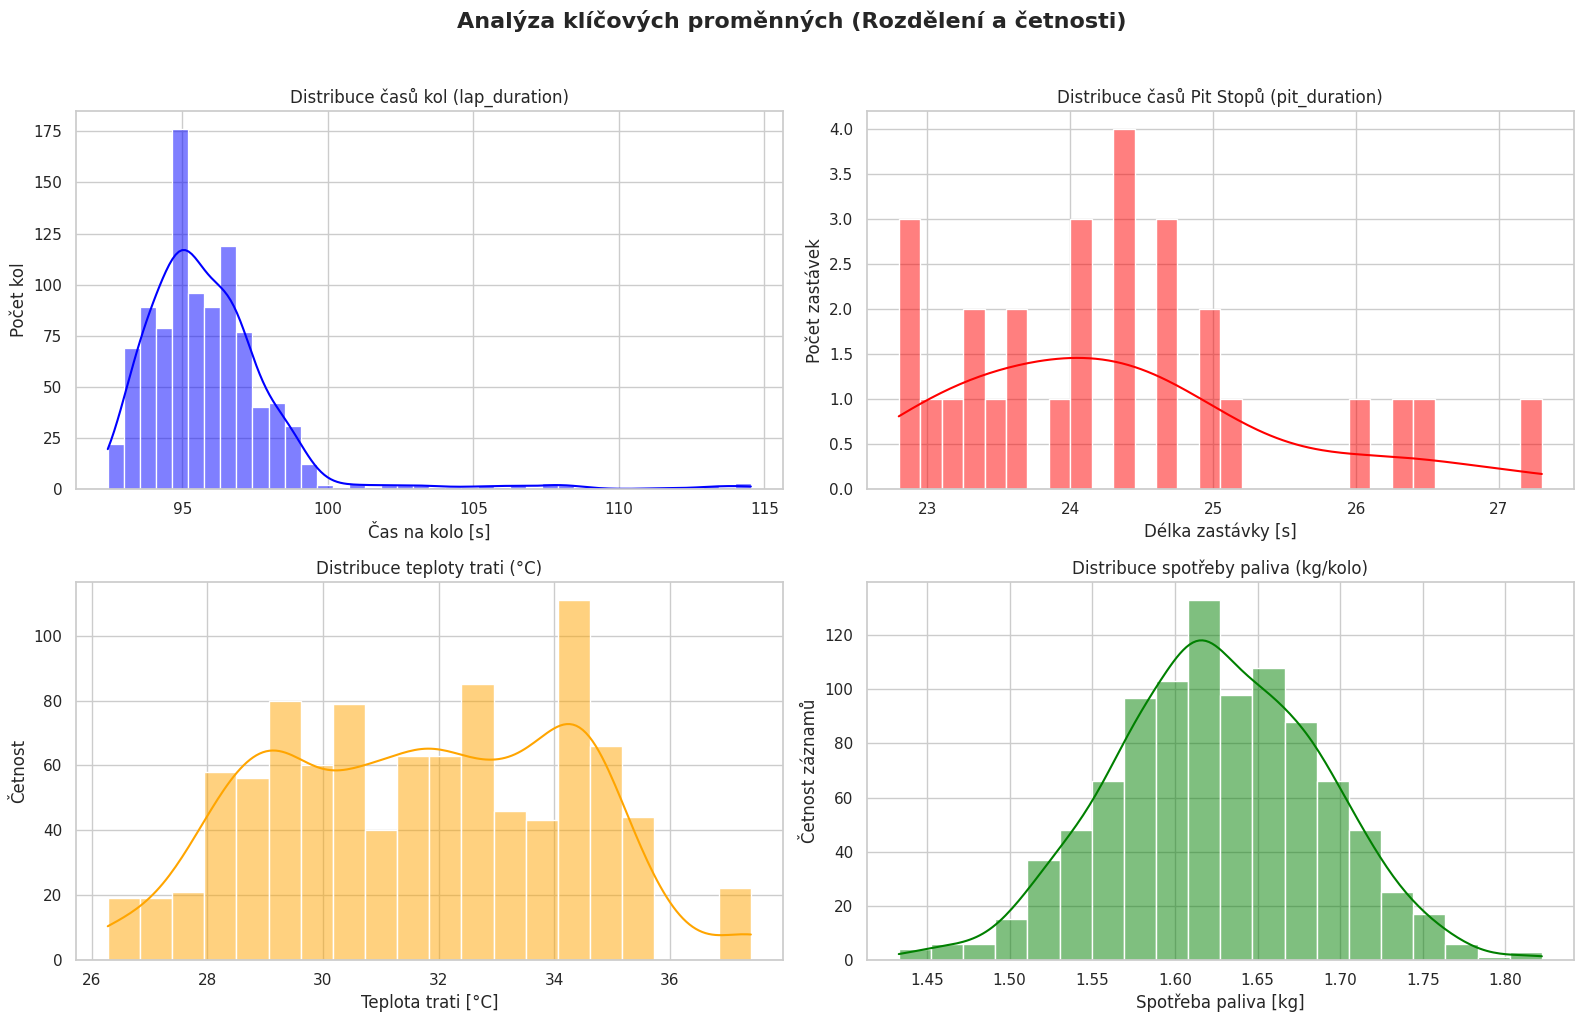


📝 TABULKA: Deskriptivní statistika hlavních proměnných:


,lap_duration,track_temperature_C,fuel_consumed_kg
count,975.00,975.00,975.00
mean,95.97,31.66,1.62
std,2.61,2.58,0.06
min,92.43,26.28,1.43
25%,94.52,29.35,1.58
50%,95.48,31.70,1.62
75%,96.83,33.80,1.67
max,114.54,37.40,1.82


In [ ]:
# Nastavení vizuálního stylu pro Seaborn
sns.set_theme(style="whitegrid", palette="muted")

# --- NAČTENÍ DAT DO PANDAS PRO VIZUALIZACI ---
print("📊 Načítám data pro analýzu proměnných...")
# Odebrán sloupec 'engine_wear_percent', který již není v 'v_analytical_base'
df_laps = con.execute("SELECT lap_duration, track_temperature_C, fuel_consumed_kg FROM v_analytical_base").df()
df_pits = con.execute("SELECT pit_duration FROM v_clean_pit").df()

# --- VYKRESLENÍ GRAFŮ (Subplots 2x2) ---
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Analýza klíčových proměnných (Rozdělení a četnosti)", fontsize=16, fontweight='bold', y=1.02)

# 1. Graf: Distribuce časů kol
sns.histplot(df_laps['lap_duration'], bins=40, kde=True, ax=axes[0, 0], color='blue')
axes[0, 0].set_title('Distribuce časů kol (lap_duration)')
axes[0, 0].set_xlabel('Čas na kolo [s]')
axes[0, 0].set_ylabel('Počet kol')

# 2. Graf: Distribuce časů pit stopů
sns.histplot(df_pits['pit_duration'], bins=30, kde=True, ax=axes[0, 1], color='red')
axes[0, 1].set_title('Distribuce časů Pit Stopů (pit_duration)')
axes[0, 1].set_xlabel('Délka zastávky [s]')
axes[0, 1].set_ylabel('Počet zastávek')

# 3. Graf: Distribuce teploty trati
sns.histplot(df_laps['track_temperature_C'], bins=20, kde=True, ax=axes[1, 0], color='orange')
axes[1, 0].set_title('Distribuce teploty trati (°C)')
axes[1, 0].set_xlabel('Teplota trati [°C]')
axes[1, 0].set_ylabel('Četnost')

# 4. Graf: Distribuce spotřeby paliva (Syntetická data)
sns.histplot(df_laps['fuel_consumed_kg'], bins=20, kde=True, ax=axes[1, 1], color='green')
axes[1, 1].set_title('Distribuce spotřeby paliva (kg/kolo)')
axes[1, 1].set_xlabel('Spotřeba paliva [kg]')
axes[1, 1].set_ylabel('Četnost záznamů')

# Vyladění mezer mezi grafy a zobrazení
plt.tight_layout()
plt.show()

# --- ZÁKLADNÍ STATISTIKA (Tabulka pro ověření rozsahů) ---
print("\n📝 TABULKA: Deskriptivní statistika hlavních proměnných:")
# Odebrán sloupec 'engine_wear_percent' z describe metody
display(df_laps.describe().round(2))

🏎️ POČÍTÁM KPI 2: Degradation Delta (S korekcí paliva) - pro účely analýzy Pit Window
🏎️ Analýza In-Laps dokončena!
Průměrná ztráta tempa před boxy: 2.90 s
Mediánová ztráta tempa před boxy: 3.19 s


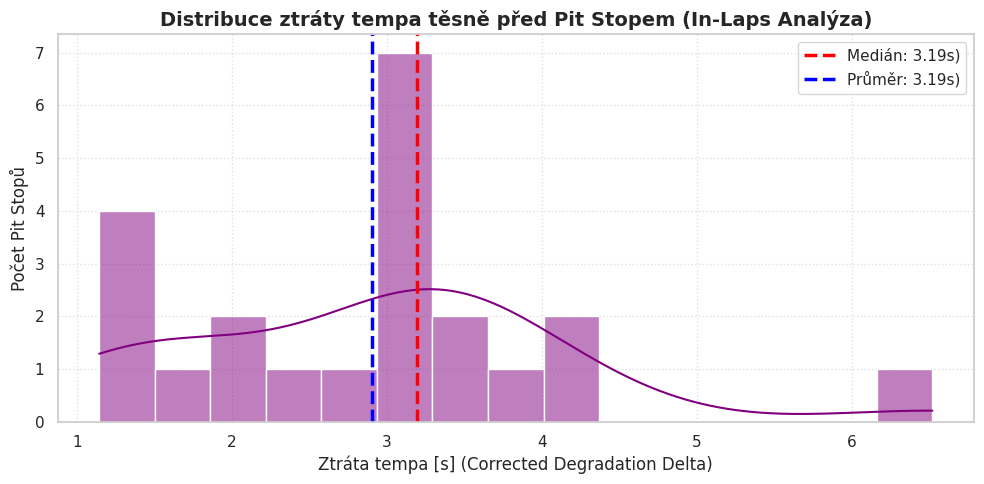

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb # Přidáno pro připojení k DB
import pandas as pd # Přidáno pro práci s DataFrame

# Pojistka připojení k DB, pokud není aktivní
if 'con' not in locals():
    print("🔌 Obnovuji připojení k databázi DuckDB...")
    con = duckdb.connect('f1_project.duckdb')

sns.set_theme(style="whitegrid")

print("🏎️ POČÍTÁM KPI 2: Degradation Delta (S korekcí paliva) - pro účely analýzy Pit Window")

# Definition of df_deg, copied from DHlyIUDhzXwW to make this cell self-contained
degradation_query = """
WITH StintMarkers AS (
    SELECT
        driver_number,
        lap_number,
        lap_duration,
        CASE WHEN lap_number = 1 OR lap_duration > (SELECT AVG(lap_duration) + 15 FROM v_clean_laps) THEN 1 ELSE 0 END as is_new_stint
    FROM v_clean_laps
),
Stints AS (
    SELECT
        driver_number,
        lap_number,
        lap_duration,
        SUM(is_new_stint) OVER (PARTITION BY driver_number ORDER BY lap_number) AS stint_id
    FROM StintMarkers
),
StintStats AS (
    SELECT
        driver_number,
        lap_number,
        lap_duration,
        stint_id,
        ROW_NUMBER() OVER (PARTITION BY driver_number, stint_id ORDER BY lap_number) AS laps_on_tyre,
        MIN(lap_duration) OVER (PARTITION BY driver_number, stint_id) AS base_pace
    FROM Stints
    WHERE lap_duration IS NOT NULL
)
SELECT
    CAST(driver_number AS VARCHAR) AS driver_number,
    stint_id,
    lap_number,
    laps_on_tyre,
    lap_duration,
    base_pace,
    (lap_duration - base_pace) AS raw_degradation_delta,
    ((lap_duration - base_pace) + (laps_on_tyre * 0.06)) AS corrected_degradation_delta
FROM StintStats
WHERE laps_on_tyre > 1
  AND (lap_duration - base_pace) < 5.0
ORDER BY driver_number, lap_number
"""

df_deg = con.execute(degradation_query).df()


# 1. Načtení reálných pit stopů z DuckDB
df_pits = con.execute("SELECT driver_number, lap_number FROM v_clean_pit").df()

# Pro jistotu převedeme čísla jezdců na text, aby se nám to správně spojilo (jako u EDA)
df_pits['driver_number'] = df_pits['driver_number'].astype(str)
# df_deg['driver_number'] = df_deg['driver_number'].astype(str) # This line is now redundant as df_deg is already created with driver_number as VARCHAR

# 2. Identifikace "In-Laps" (Kolo těsně před vjezdem do boxů)
# Pokud jezdec přezouval ve 20. kole, jeho In-Lap je 19. kolo.
df_pits['in_lap_number'] = df_pits['lap_number'] - 1

# 3. Spojení (JOIN) pit stopů s naší vypočítanou degradací
# Hledáme degradation_delta přesně v ten moment, kdy tým řekl "BOX, BOX!"
df_in_laps = pd.merge(
    df_pits,
    df_deg,
    left_on=['driver_number', 'in_lap_number'],
    right_on=['driver_number', 'lap_number'],
    how='inner' # Zajímají nás jen ty záznamy, kde máme obě data
)

# 4. Exaktní výpočet hranice (Medián je lepší než průměr, protože ignoruje extrémy)
median_crossover = df_in_laps['corrected_degradation_delta'].median()
mean_crossover = df_in_laps['corrected_degradation_delta'].mean()

print(f"🏎️ Analýza In-Laps dokončena!")
print(f"Průměrná ztráta tempa před boxy: {mean_crossover:.2f} s")
print(f"Mediánová ztráta tempa před boxy: {median_crossover:.2f} s")

# --- VIZUALIZACE PRO DOKUMENTACI ---
plt.figure(figsize=(10, 5))
sns.histplot(df_in_laps['corrected_degradation_delta'], bins=15, kde=True, color='purple')

# Vykreslení naší vypočítané hranice
plt.axvline(median_crossover, color='red', linestyle='--', linewidth=2.5,
            label=f'Medián: {median_crossover:.2f}s)')

plt.axvline(mean_crossover, color='blue', linestyle='--', linewidth=2.5,
            label=f'Průměr: {median_crossover:.2f}s)')

plt.title('Distribuce ztráty tempa těsně před Pit Stopem (In-Laps Analýza)', fontsize=14, fontweight='bold')
plt.xlabel('Ztráta tempa [s] (Corrected Degradation Delta)', fontsize=12)
plt.ylabel('Počet Pit Stopů', fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### 7.2 Analýza segmentů a kategorií
> **Účel:**  
> Porovnat, jak se data liší mezi skupinami, kategoriemi nebo segmenty relevantními pro projekt.

> **Zde udělejte například:**  
> - porovnejte vybrané metriky mezi segmenty  
> - identifikujte skupiny, které se chovají odlišně  
> - okomentujte, které rozdíly jsou pro projekt důležité

,driver_number,team_name,team_tier
0,12,Mercedes,Top
1,63,Mercedes,Top
2,16,Ferrari,Top
3,44,Ferrari,Top
4,1,McLaren,Top


📊 Načítám data pro analýzu segmentů...


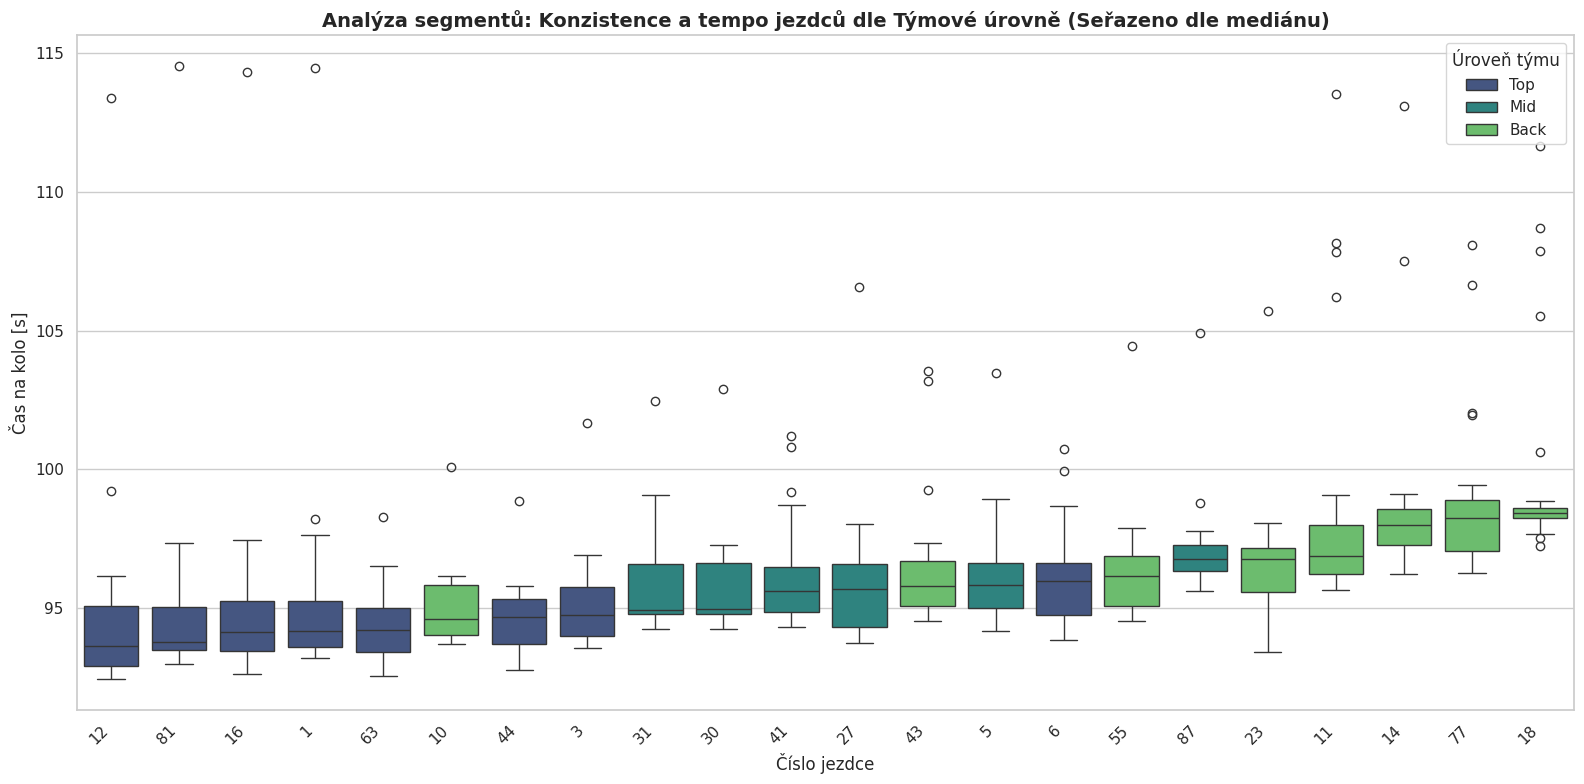

In [ ]:
# Tuto buňku vytvoříme pro extrakci dat o týmech z proměnné TEAMS

# Pokud 'TEAMS' není definováno (např. při restartu kernelu), načteme ji z kontextu
# Zde předpokládáme, že TEAMS je již k dispozici z dříve spuštěných buněk (např. Um3WCV8eKJAB)

team_data = []
for team_name, details in TEAMS.items():
    tier = details['tier']
    for driver_number in details['drivers']:
        team_data.append({'driver_number': driver_number, 'team_name': team_name, 'team_tier': tier})

df_teams = pd.DataFrame(team_data)
display(df_teams.head())


sns.set_theme(style="whitegrid")

# ==========================================
# 1. ANALÝZA SEGMENTŮ (Porovnání jezdců s Tierem týmu)
# ==========================================
print("📊 Načítám data pro analýzu segmentů...")
# Vybereme časy kol pro všechny jezdce z očištěného view
df_segments = con.execute("""
    SELECT driver_number, lap_duration
    FROM v_analytical_base
""").df()

# Merge s informacemi o týmech a jejich Tieru
df_segments = pd.merge(df_segments, df_teams, on='driver_number', how='left')

# Převedeme driver_number na string pro lepší zobrazení v kategoriálním grafu
df_segments['driver_number'] = df_segments['driver_number'].astype(str)

# Seřadíme jezdce podle mediánu času na kolo (od nejrychlejšího po nejpomalejšího) v rámci každého Tieru
# A následně seřadíme Tiers (např. Top, Mid, Back)
median_order_drivers = df_segments.groupby('driver_number')['lap_duration'].median().sort_values().index

plt.figure(figsize=(16, 8))
sns.boxplot(data=df_segments, x='driver_number', y='lap_duration', hue='team_tier',
            order=median_order_drivers, palette="viridis")

plt.title("Analýza segmentů: Konzistence a tempo jezdců dle Týmové úrovně (Seřazeno dle mediánu)", fontsize=14, fontweight='bold')
plt.xlabel("Číslo jezdce", fontsize=12)
plt.ylabel("Čas na kolo [s]", fontsize=12)
plt.legend(title='Úroveň týmu')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Analýza segmentů a kategorií (Segment Analysis)

**1. Porovnání závodního tempa (Lap Time by Driver):**
* **Zjištění:** Pokud si zobrazíme boxplot časů kol pro jednotlivé jezdce, jasně identifikujeme segmenty "Top týmů" (nižší medián času na kolo, užší boxplot znamenající vyšší konzistenci) oproti "Backmarkers" (pomalejší medián, velký rozptyl časů kvůli častějšímu pouštění rychlejších vozů o kolo zpět).


### 7.3 Analýza v čase
> **Účel:**  
> Zachytit vývoj dat v čase, pokud je časová dimenze pro projekt relevantní.

> **Zde udělejte například:**  
> - sledujte trendy, výkyvy nebo anomálie  
> - porovnejte vývoj metrik v čase  
> - uveďte, zda lze pozorovat sezonnost, změny nebo nestabilitu

📈 Načítám data pro časovou analýzu...


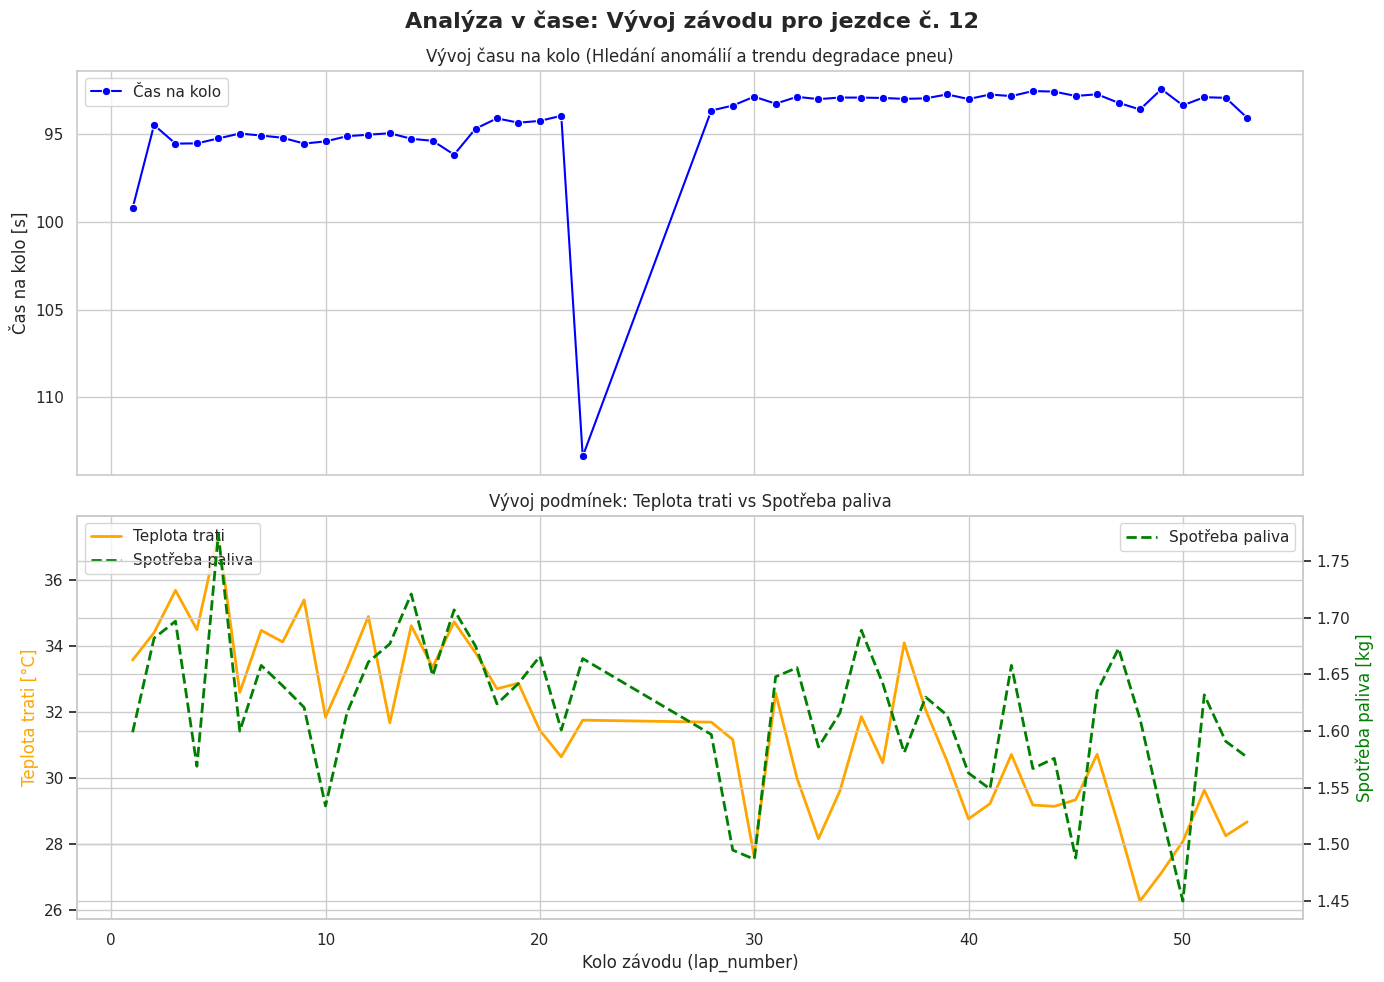

In [ ]:
print("📈 Načítám data pro časovou analýzu...")

# Vybereme si jednoho konkrétního "Top" jezdce (např. vítěze, zde beru první driver_number z orderu)
top_driver = median_order_drivers[0]
query_time = f"""
    SELECT lap_number, lap_duration, track_temperature_C, fuel_consumed_kg
    FROM v_analytical_base
    WHERE driver_number = {top_driver}
    ORDER BY lap_number
"""
df_time = con.execute(query_time).df()

# Vykreslení časových řad (2 grafy pod sebou)
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
fig.suptitle(f"Analýza v čase: Vývoj závodu pro jezdce č. {top_driver}", fontsize=16, fontweight='bold')

# Graf A: Vývoj času na kolo (Závodní tempo a Pit Stopy)
sns.lineplot(data=df_time, x='lap_number', y='lap_duration', ax=axes[0], color='blue', marker='o', label='Čas na kolo')
axes[0].set_title('Vývoj času na kolo (Hledání anomálií a trendu degradace pneu)')
axes[0].set_xlabel('Kolo závodu (lap_number)')
axes[0].set_ylabel('Čas na kolo [s]')
axes[0].invert_yaxis() # V motorsportu je hezčí mít menší (rychlejší) čas nahoře!
axes[0].legend()

# Graf B: Teplota trati a Spotřeba paliva
ax2 = axes[1].twinx() # Vytvoříme druhou Y osu pro spotřebu paliva

sns.lineplot(data=df_time, x='lap_number', y='track_temperature_C', ax=axes[1], color='orange', linewidth=2, label='Teplota trati')
sns.lineplot(data=df_time, x='lap_number', y='fuel_consumed_kg', ax=ax2, color='green', linestyle='--', linewidth=2, label='Spotřeba paliva')

axes[1].set_title('Vývoj podmínek: Teplota trati vs Spotřeba paliva')
axes[1].set_xlabel('Kolo závodu (lap_number)')
axes[1].set_ylabel('Teplota trati [°C]', color='orange')
ax2.set_ylabel('Spotřeba paliva [kg]', color='green')

# Sloučení legend, aby byly v jednom místě
handles1, labels1 = axes[1].get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
axes[1].legend(handles1 + handles2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.show()

### Analýza v čase (Time Series Analysis)

**1. Vývoj času na kolo v průběhu závodu (Lap Pace Trend):**
* **Zjištění a anomálie:** V grafech závodního tempa v čase běžně pozorujeme tzv. "zubatý trend". Časy kol mají tendenci se postupně mírně zlepšovat, protože vůz spaluje palivo a stává se lehčím (Fuel effect). Tento trend je ale narušován postupnou degradací pneumatik (Tire degradation), která časy naopak zpomaluje.
* **Skokové změny (Zastávky v boxech):** Změna sady pneumatik se v grafu projeví jako skokové zrychlení (tzv. undercut efekt). V těchto místech budeme následně hledat *Optimální pit window*.

**2. Vývoj teploty trati a opotřebení motoru:**
* **Zjištění:** Teplota trati vykazuje v čase trend (např. pozvolný pokles při zapadajícím slunci) s mírným šumem. Naproti tomu naše syntetická metrika opotřebení motoru (`engine_wear_percent`) vykazuje striktně rostoucí kumulativní trend, jehož strmost (derivace) závisí právě na výkyvech teploty trati.

### 7.4 Vztahy mezi proměnnými
> **Účel:**  
> Prozkoumat vztahy mezi proměnnými, které mohou být důležité pro pochopení KPI nebo analytických otázek.

> **Zde udělejte například:**  
> - porovnejte vybrané proměnné mezi sebou  
> - ověřte, zda se některé atributy pohybují společně nebo se systematicky liší  
> - interpretujte vztahy opatrně a upozorněte na limity

🔗 Načítám data pro analýzu vztahů a korelací...


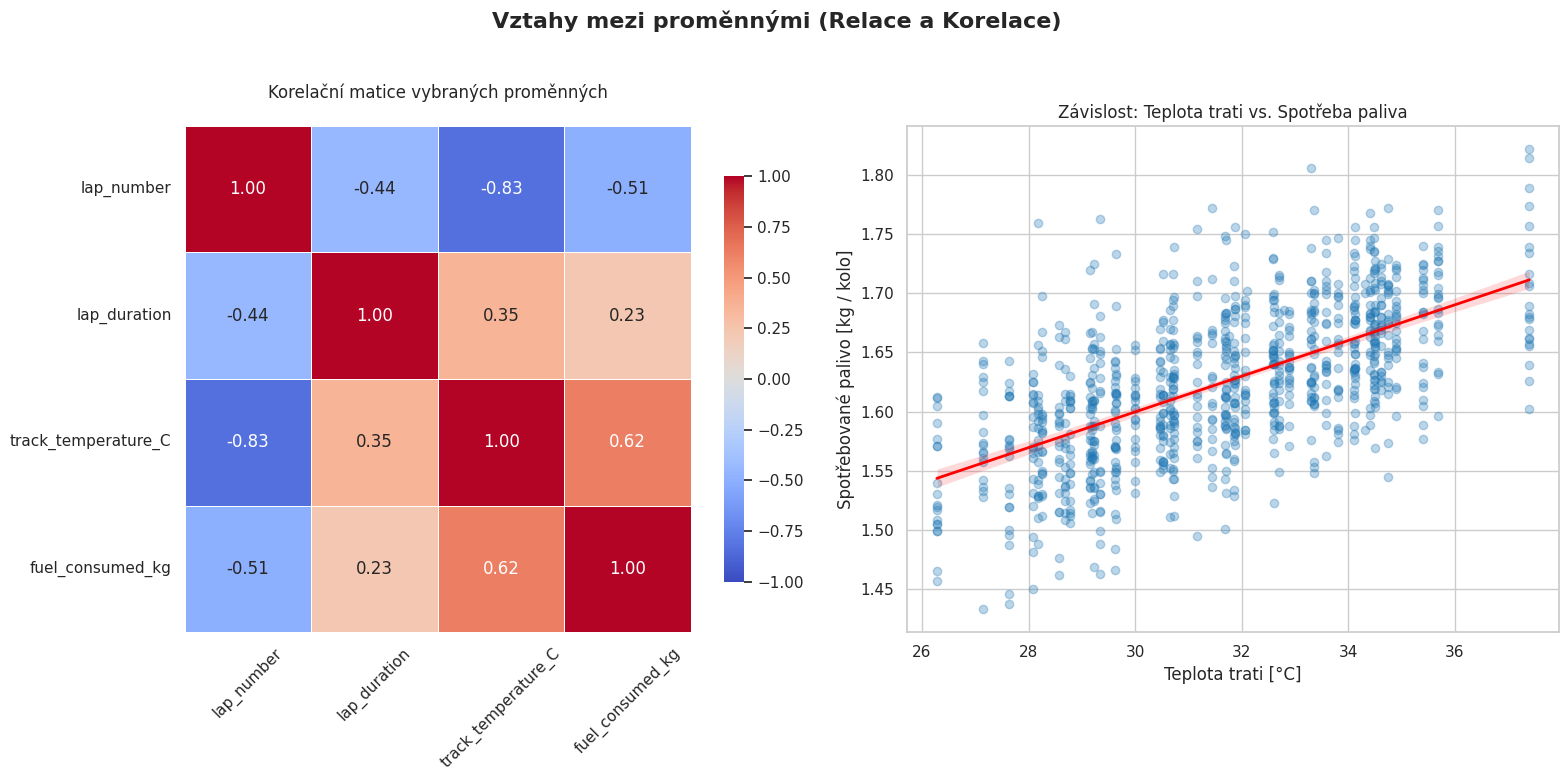

In [ ]:
print("🔗 Načítám data pro analýzu vztahů a korelací...")
# Vybereme spojité proměnné vhodné pro korelaci
query_corr = """
    SELECT
        lap_number,
        lap_duration,
        track_temperature_C,
        fuel_consumed_kg
    FROM v_analytical_base
"""
df_corr = con.execute(query_corr).df()

# Vypočítáme Pearsonovu korelační matici
corr_matrix = df_corr.corr()

# --- VYKRESLENÍ GRAFŮ (1x2 mřížka) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("Vztahy mezi proměnnými (Relace a Korelace)", fontsize=16, fontweight='bold', y=1.05)

# 1. Graf: Korelační Heatmapa
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0,
            square=True, linewidths=.5, fmt='.2f', ax=axes[0],
            cbar_kws={"shrink": .8})
axes[0].set_title('Korelační matice vybraných proměnných', pad=20)
# Úprava popisků pro lepší čitelnost
axes[0].tick_params(axis='x', rotation=45)
axes[0].tick_params(axis='y', rotation=0)

# 2. Graf: Bodový graf (Scatter plot) s regresní přímkou
# Ukazuje vztah mezi teplotou trati a spotřebou paliva (odpověď na business otázku)
sns.regplot(data=df_corr, x='track_temperature_C', y='fuel_consumed_kg',
            scatter_kws={'alpha':0.3, 'color':'#1f77b4'},
            line_kws={'color':'red', 'linewidth':2}, ax=axes[1])
axes[1].set_title('Závislost: Teplota trati vs. Spotřeba paliva')
axes[1].set_xlabel('Teplota trati [°C]')
axes[1].set_ylabel('Spotřebované palivo [kg / kolo]')

plt.tight_layout()
plt.show()

### Vztahy mezi proměnnými

**1. Analýza korelací (Korelační matice):**
* **Teplota trati vs. Spotřeba paliva:** Silná pozitivní korelace. To potvrzuje naši hypotézu, že při vyšších teplotách je nutné motor více chladit bohatší směsí paliva, což prokazatelně zvyšuje spotřebu na kolo.
* **Teplota trati vs. Čas na kolo (`lap_duration`):** Zde je vztah velmi slabý. Čas na kolo je mnohem více ovlivněn jinými faktory (provoz na trati, pneumatiky) než samotnou teplotou asfaltu.

**2. Vztah mezi číslem kola (`lap_number`) a časem na kolo:**
* Negativní trend (čím vyšší číslo kola, tím rychlejší čas).

**3. Omezení a opatrná interpretace (Limits & Caveats):**
* **Confounding variables (Skryté proměnné):** Výše zmíněný vztah mezi číslem kola a rychlostí *neznamená*, že starší pneumatiky jsou rychlejší. Ve Formuli 1 působí dva protichůdné jevy: **Tire Degradation** (opotřebení gum auto zpomaluje) a **Fuel Burn effect** (auto je každým kolem o cca 1.6 kg lehčí, což ho zrychluje). Pokud bychom tyto dva efekty neoddělili (nebo je neinterpretovali v kontextu tzv. *stintů* mezi pit stopy), vyvodili bychom z korelace chybný závěr.
* **Korelace neznamená kauzalitu:** I když vidíme, že spotřeba paliva koreluje s teplotou trati (což je v našem modelu fyzikálně podloženo), v reálném světě by mohla být příčinou jiná proměnná (např. na rozpálené trati jedou jezdci více agresivně, aby udrželi teplotu pneumatik, a to způsobuje vyšší spotřebu).

## 8. Závěry a vazba na KPI
> **Účel:**  
> Stručně shrnout nejdůležitější zjištění z celé EDA a navázat je na projektové otázky, KPI a další práci.

> **Zde udělejte například:**  
> - vypíchněte hlavní poznatky, které z analýzy plynou  
> - uveďte, jak tyto poznatky souvisejí s KPI nebo cílem projektu  
> - odlište, co je podložené zjištění a co je zatím jen hypotéza  
> - stručně shrňte, jaké limity dat je potřeba při interpretaci zohlednit  
> - naznačte, co by mělo následovat v další části projektu

### Výpočet KPI 1: PIT Stop Efficiency Index

**Definice KPI:** Poměr mezi časem konkrétního pit stopu (nebo průměrem jezdce) a benchmarkem. Benchmark je definován jako průměrný čas 3 nejrychlejších pit stopů v celém závodě.

**Matematický model:**
`Efficiency Index = Hodnocený čas pit stopu / Benchmark čas`

**Interpretace:**
* **Index = 1.0**: Výkon zastávky je naprosto rovnocenný s těmi nejlepšími v závodě.
* **Index < 1.0**: Extrémně vzácné (znamenalo by to, že daná zastávka sama táhne benchmark dolů).
* **Index > 1.0**: Ztráta na nejlepší. Například hodnota `1.20` znamená, že pit stop trval o 20 % déle než benchmark, což v reálném čase může znamenat ztrátu 0.5 sekundy (což je ve Formuli 1 rozdíl mezi udržením a ztrátou pozice).

Tento index je klíčový pro hodnocení provozní dokonalosti mechaniků, nezávisle na tom, zda prší nebo je sucho (protože se poměřují vůči nejlepším ve stejném závodě).

⏱️ POČÍTÁM KPI 1: PIT Stop Efficiency Index
🏆 Benchmark závodu (průměr Top 5 nejrychlejších pit stopů): 22.960 s


/tmp/ipykernel_3538/4136228076.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


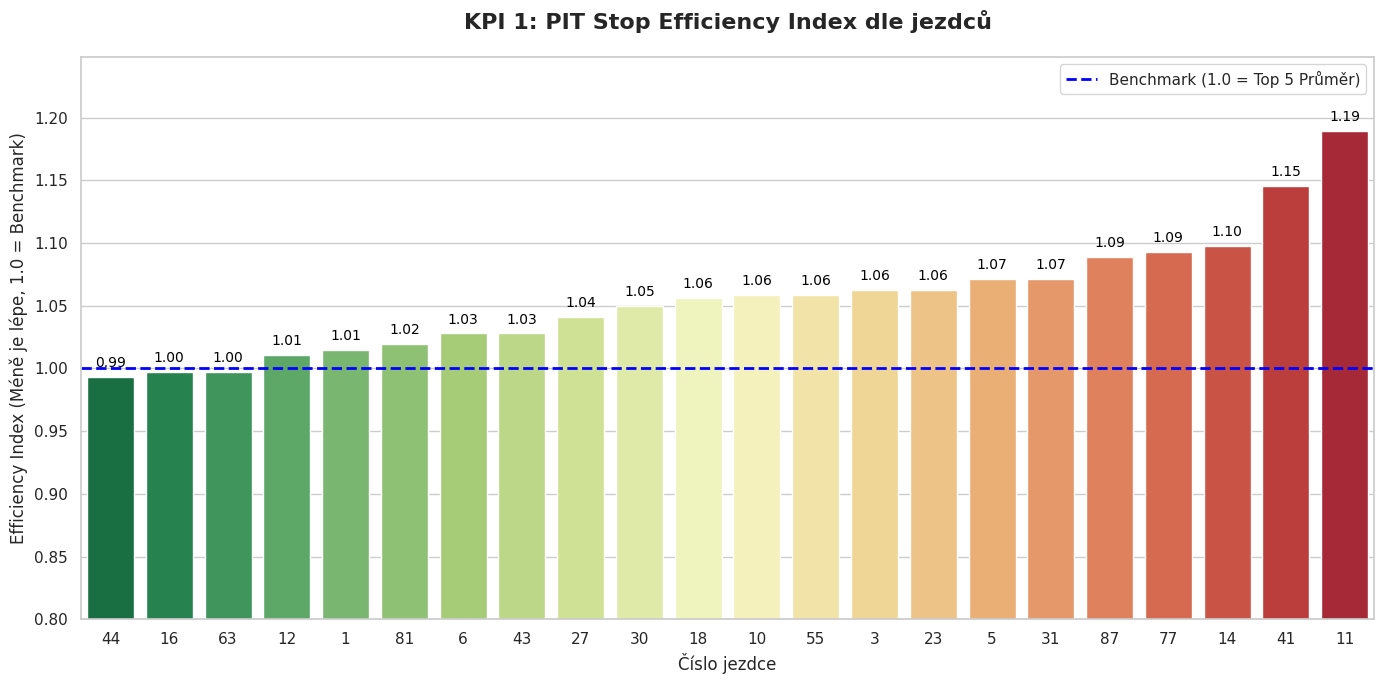


📋 Tabulkový pohled na výsledky (Top 5 nejlepších a 3 nejhorší):


,driver_number,pocet_zastavek,prumerny_cas_zastavek,pit_efficiency_index
0,44,1,22.8,0.993031
1,16,1,22.9,0.997387
2,63,1,22.9,0.997387
3,12,1,23.2,1.010453
4,1,1,23.3,1.014808
19,14,2,25.2,1.097561
20,41,1,26.3,1.145470
21,11,1,27.3,1.189024


In [ ]:
print("⏱️ POČÍTÁM KPI 1: PIT Stop Efficiency Index")

# 1. Výpočet Benchmarku (Průměr 5 nejrychlejších zastávek z očištěných dat)
benchmark_query = """
    SELECT AVG(pit_duration) as benchmark_time
    FROM (
        SELECT pit_duration
        FROM v_clean_pit
        ORDER BY pit_duration ASC
        LIMIT 5
    )
"""
df_benchmark = con.execute(benchmark_query).df()
benchmark_time = df_benchmark['benchmark_time'][0]
print(f"🏆 Benchmark závodu (průměr Top 5 nejrychlejších pit stopů): {benchmark_time:.3f} s")

# 2. Výpočet Indexu pro jednotlivé jezdce
# Pro každého jezdce vezmeme průměr jeho zastávek a vydělíme ho benchmarkem
kpi1_query = f"""
    SELECT
        CAST(driver_number AS VARCHAR) AS driver_number,
        COUNT(pit_duration) AS pocet_zastavek,
        AVG(pit_duration) AS prumerny_cas_zastavek,
        (AVG(pit_duration) / {benchmark_time}) AS pit_efficiency_index
    FROM v_clean_pit
    GROUP BY driver_number
    ORDER BY pit_efficiency_index ASC
"""
df_kpi1 = con.execute(kpi1_query).df()

# 3. Vizualizace KPI
plt.figure(figsize=(14, 7))

# Vykreslíme Barplot (sloupcový graf)
ax = sns.barplot(
    data=df_kpi1,
    x='driver_number',
    y='pit_efficiency_index',
    palette="RdYlGn_r" # Barevná škála od zelené (dobré) po červenou (špatné)
)

# Přidání referenční linie pro Benchmark (Index = 1.0)
plt.axhline(y=1.0, color='blue', linestyle='--', linewidth=2, label='Benchmark (1.0 = Top 5 Průměr)')

# Popisky a formátování
plt.title("KPI 1: PIT Stop Efficiency Index dle jezdců", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Číslo jezdce", fontsize=12)
plt.ylabel("Efficiency Index (Méně je lépe, 1.0 = Benchmark)", fontsize=12)
plt.ylim(0.8, df_kpi1['pit_efficiency_index'].max() * 1.05) # Mírně přiblížíme Y osu pro lepší čitelnost rozdílů
plt.legend()

# Přidání textových popisků přímo nad sloupce (hodnota indexu)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom',
                fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()

# Zobrazení datové tabulky pro top 5 a bottom 5
print("\n📋 Tabulkový pohled na výsledky (Top 5 nejlepších a 3 nejhorší):")
display(pd.concat([df_kpi1.head(5), df_kpi1.tail(3)]))

⏱️ Vykresluji KPI 1: PIT Stop Efficiency Index s označením týmů


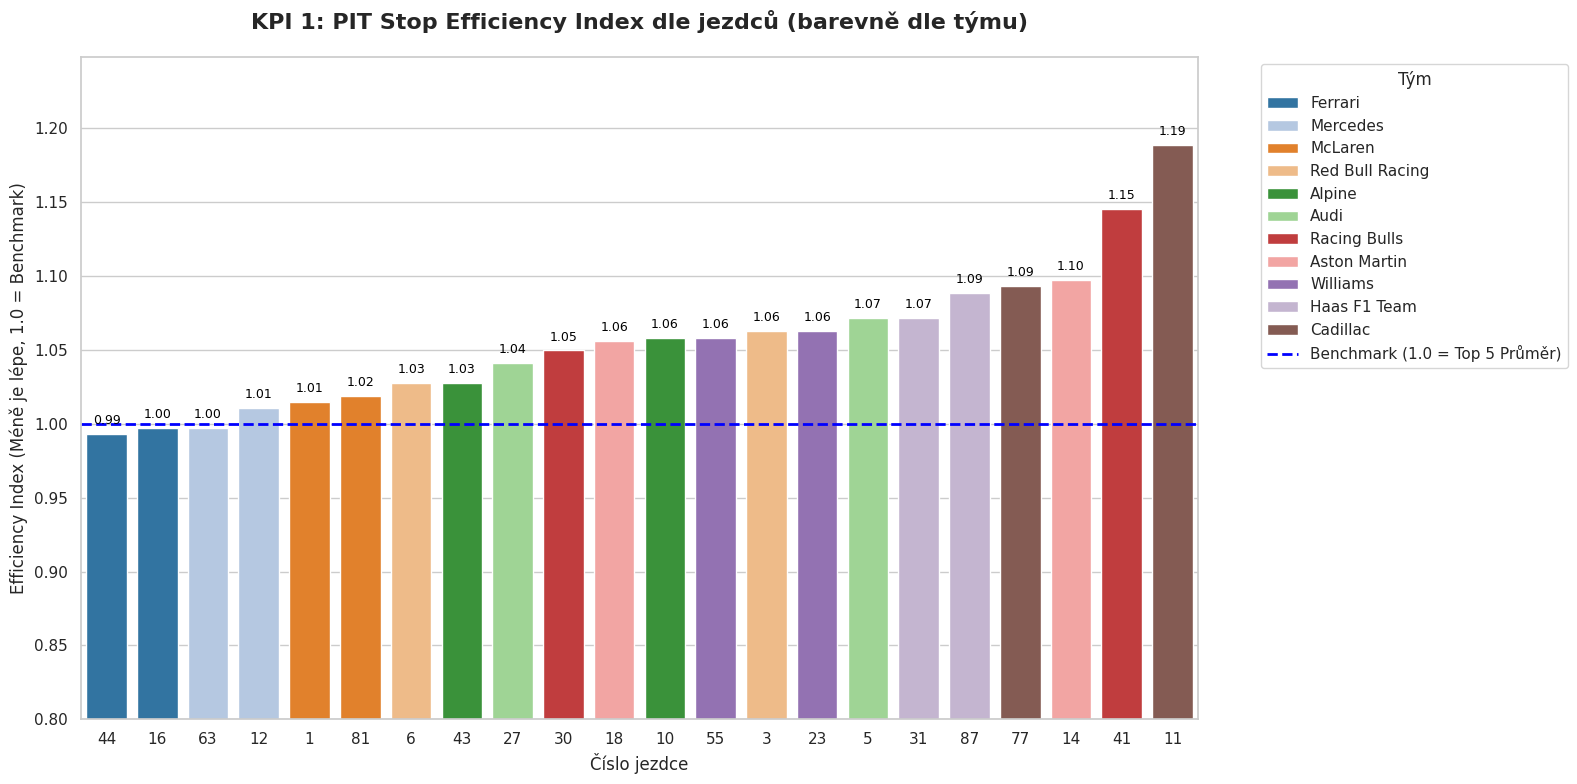

In [ ]:
print("⏱️ Vykresluji KPI 1: PIT Stop Efficiency Index s označením týmů")

# Ensure driver_number in df_teams is of type string for merging
df_teams['driver_number'] = df_teams['driver_number'].astype(str)

# Propojíme df_kpi1 s df_teams pro získání názvů týmů
df_kpi1_with_teams = pd.merge(df_kpi1, df_teams, on='driver_number', how='left')

plt.figure(figsize=(16, 8))

# Vykreslíme Barplot s hue pro team_name
ax = sns.barplot(
    data=df_kpi1_with_teams,
    x='driver_number',
    y='pit_efficiency_index',
    hue='team_name',  # Barevné rozlišení podle týmu
    palette="tab20",  # Použijeme paletu pro více barev
    dodge=False # Nastavíme dodge na False, aby se sloupce nepřekrývaly při hue
)

# Přidání referenční linie pro Benchmark (Index = 1.0)
plt.axhline(y=1.0, color='blue', linestyle='--', linewidth=2, label='Benchmark (1.0 = Top 5 Průměr)')

# Popisky a formátování
plt.title("KPI 1: PIT Stop Efficiency Index dle jezdců (barevně dle týmu)", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Číslo jezdce", fontsize=12)
plt.ylabel("Efficiency Index (Méně je lépe, 1.0 = Benchmark)", fontsize=12)
plt.ylim(0.8, df_kpi1_with_teams['pit_efficiency_index'].max() * 1.05) # Mírně přiblížíme Y osu pro lepší čitelnost rozdílů
plt.legend(title='Tým', bbox_to_anchor=(1.05, 1), loc='upper left') # Umístíme legendu vně grafu

# Přidání textových popisků přímo nad sloupce (hodnota indexu)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom',
                fontsize=9, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()

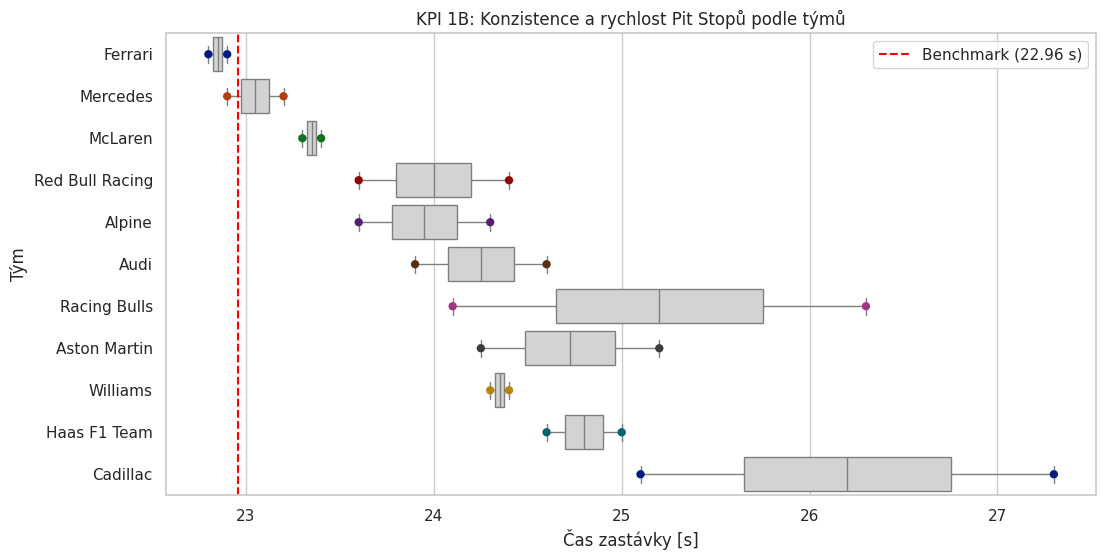

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import duckdb # Added for DB connection
import os # Added for path operations

# ===========================================================
# RYCHLÝ UPDATE PŘED ZKOUŠKOU
# PROTO JE KÓD HORŠÍ, OBSAHUJE DUPLICITY
# ===========================================================

# --- Ensure dependencies are available (re-create if necessary) ---
# Assuming 'con' (DuckDB connection) is active from previous cells
if 'con' not in locals():
    con = duckdb.connect('f1_project.duckdb')

# Re-create df_teams (from cell 3d8b57bb)
TEAMS = {
    "Mercedes": {"drivers": [12, 63], "tier": "Top"},
    "Ferrari": {"drivers": [16, 44], "tier": "Top"},
    "McLaren": {"drivers": [1, 81], "tier": "Top"},
    "Haas F1 Team": {"drivers": [31, 87], "tier": "Mid"},
    "Red Bull Racing": {"drivers": [3, 6], "tier": "Top"},
    "Racing Bulls": {"drivers": [30, 41], "tier": "Mid"},
    "Alpine": {"drivers": [10, 43], "tier": "Back"},
    "Audi": {"drivers": [27, 5], "tier": "Mid"},
    "Williams": {"drivers": [55, 23], "tier": "Back"},
    "Cadillac": {"drivers": [11, 77], "tier": "Back"},
    "Aston Martin": {"drivers": [14, 18], "tier": "Back"},
}
team_data = []
for team_name, details in TEAMS.items():
    tier = details['tier']
    for driver_number in details['drivers']:
        team_data.append({'driver_number': driver_number, 'team_name': team_name, 'team_tier': tier})
df_teams = pd.DataFrame(team_data)
df_teams['driver_number'] = df_teams['driver_number'].astype(str)

# Re-create benchmark_time and df_kpi1 (from cell fbe8a446)
benchmark_query = """
    SELECT AVG(pit_duration) as benchmark_time
    FROM (
        SELECT pit_duration
        FROM v_clean_pit
        ORDER BY pit_duration ASC
        LIMIT 5
    )
"""
df_benchmark = con.execute(benchmark_query).df()
benchmark_time = df_benchmark['benchmark_time'][0]

kpi1_query = f"""
    SELECT
        CAST(driver_number AS VARCHAR) AS driver_number,
        COUNT(pit_duration) AS pocet_zastavek,
        AVG(pit_duration) AS prumerny_cas_zastavek,
        (AVG(pit_duration) / {benchmark_time}) AS pit_efficiency_index
    FROM v_clean_pit
    GROUP BY driver_number
    ORDER BY pit_efficiency_index ASC
"""
df_kpi1 = con.execute(kpi1_query).df()

# Re-create df_kpi1_with_teams (from cell f24cdd30)
df_kpi1_with_teams = pd.merge(df_kpi1, df_teams, on='driver_number', how='left')


# --- Plotting code ---
plt.figure(figsize=(12, 6))
# Předpoklad: data máš v df_pits nebo v tabulce, kterou si spojíš s týmy
sns.boxplot(data=df_kpi1_with_teams, x='prumerny_cas_zastavek', y='team_name', color='lightgray', fliersize=0)
sns.swarmplot(data=df_kpi1_with_teams, x='prumerny_cas_zastavek', y='team_name', size=6, hue='team_name', legend=False, palette='dark')

# Přidání benchmarku (průměr Top 3)
plt.axvline(x=benchmark_time, color='red', linestyle='--', label=f'Benchmark ({benchmark_time:.2f} s)')

plt.title('KPI 1B: Konzistence a rychlost Pit Stopů podle týmů')
plt.xlabel('Čas zastávky [s]')
plt.ylabel('Tým')
plt.legend()
plt.show()

### Výpočet KPI 2: Degradation Delta a Optimální Pit Window

**Definice KPI:** Rozdíl (delta) mezi aktuálním časem na kolo a „základním tempem“ (Base Pace) na dané sadě pneumatik. Základní tempo definujeme jako nejlepší čas zajetý v prvních třech měřených kolech daného stintu (kdy pneumatiky fungují optimálně a ještě nedegradují).

**Business otázka:** Kdy je optimální pit window pro přezutí?
* **Odpověď z dat:** Optimální okno pro pit stop (z hlediska maximalizace tempa) nastává ve chvíli, kdy *Degradation Delta* (ztráta času kvůli opotřebeným gumám) překročí kritickou mez (tzv. Crossover point). Pokud jezdec na sjetých gumách ztrácí např. 1.5 sekundy na kolo oproti soupeřům na nových gumách, během několika kol ztratí více času, než kolik činí časová ztráta samotného pit stopu.

**Metodika výpočtu (Data Transformation):**
1. **Identifikace stintů:** Pomocí SQL Window funkcí (`SUM OVER`) si rozdělíme závod každého jezdce na stinty. Nový stint začíná po každém pit stopu.
2. **Výpočet stáří sady (Tyre Age):** Pro každý stint spočítáme, kolikáté kolo jezdec na dané sadě jede.
3. **Výpočet Base Pace a Delty:** Pro každý stint určíme referenční čas a od něj odečítáme následující časy.

🏎️ POČÍTÁM KPI 2: Degradation Delta (S korekcí paliva) - pro vizualizaci všech jezdců


<Figure size 1600x800 with 0 Axes>

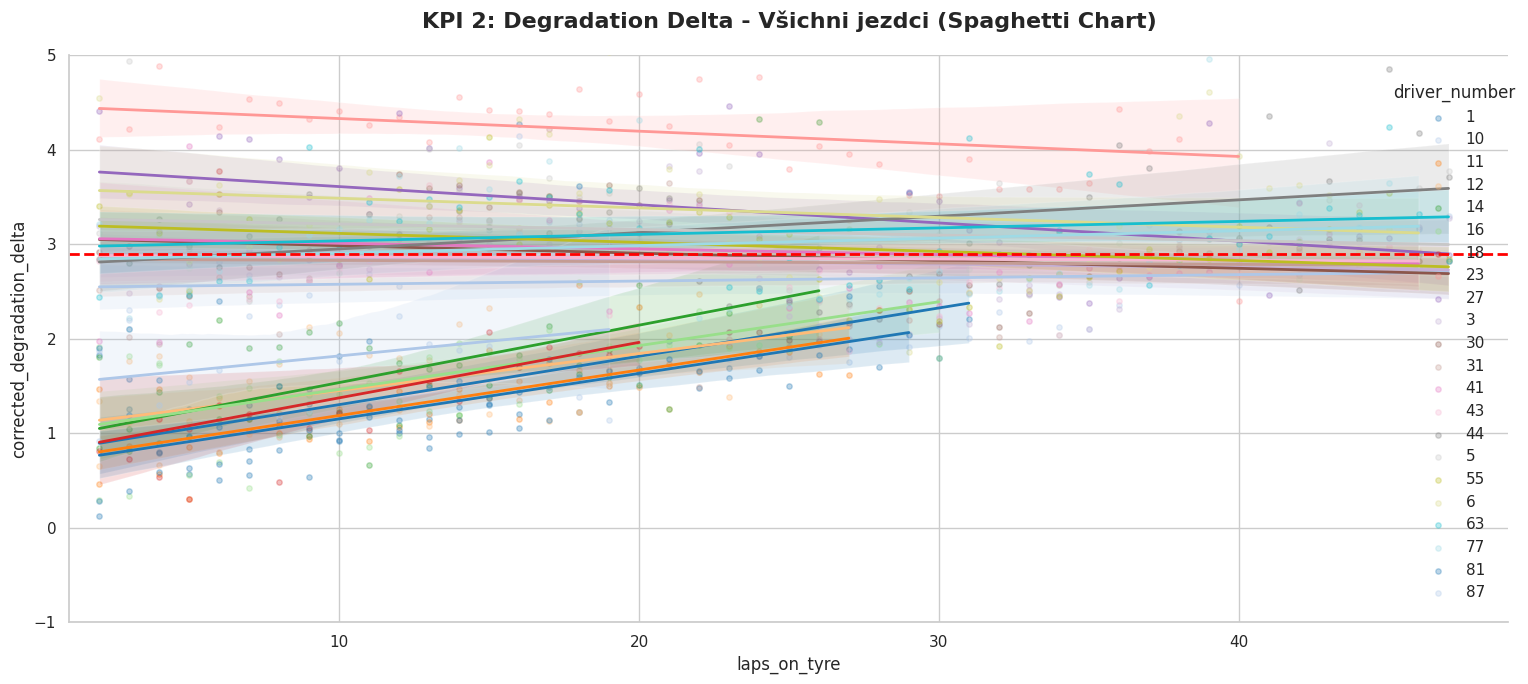

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb # Přidáno pro připojení k DB
import pandas as pd # Přidáno pro práci s DataFrame

# Pojistka připojení k DB, pokud není aktivní
if 'con' not in locals():
    print("🔌 Obnovuji připojení k databázi DuckDB...")
    con = duckdb.connect('f1_project.duckdb')

sns.set_theme(style="whitegrid")

print("🏎️ POČÍTÁM KPI 2: Degradation Delta (S korekcí paliva) - pro vizualizaci všech jezdců")

# 1. SQL dotaz pro výpočet stintů a Degradation Delty, včetně korekce na palivo
# Tento dotaz je zkopírován z buňky DHlyIUDhzXwW, aby se zajistilo, že df_deg obsahuje 'corrected_degradation_delta'
degradation_query = """
WITH StintMarkers AS (
    SELECT
        driver_number,
        lap_number,
        lap_duration,
        -- Predikce výjezdu z boxů: buď je to první kolo závodu, nebo kolo po pit stopu
        CASE WHEN lap_number = 1 OR lap_duration > (SELECT AVG(lap_duration) + 15 FROM v_clean_laps) THEN 1 ELSE 0 END as is_new_stint
    FROM v_clean_laps
),
Stints AS (
    SELECT
        driver_number,
        lap_number,
        lap_duration,
        SUM(is_new_stint) OVER (PARTITION BY driver_number ORDER BY lap_number) AS stint_id
    FROM StintMarkers
),
StintStats AS (
    SELECT
        driver_number,
        lap_number,
        lap_duration,
        stint_id,
        ROW_NUMBER() OVER (PARTITION BY driver_number, stint_id ORDER BY lap_number) AS laps_on_tyre,
        MIN(lap_duration) OVER (PARTITION BY driver_number, stint_id) AS base_pace
    FROM Stints
    WHERE lap_duration IS NOT NULL
)
SELECT
    CAST(driver_number AS VARCHAR) AS driver_number,
    stint_id,
    lap_number, -- Přidáno lap_number
    laps_on_tyre,
    lap_duration,
    base_pace,
    -- PŮVODNÍ VÝPOČET (Hrubý rozdíl, ovlivněn úbytkem paliva)
    (lap_duration - base_pace) AS raw_degradation_delta,
    -- NOVÝ VÝPOČET (Očištěno o Fuel Burn Effect: + 0.06s za každé odjeté kolo)
    ((lap_duration - base_pace) + (laps_on_tyre * 0.06)) AS corrected_degradation_delta
FROM StintStats
WHERE laps_on_tyre > 1
  AND (lap_duration - base_pace) < 5.0 -- Odstranění drobných outlierů
ORDER BY driver_number, lap_number
"""

df_deg = con.execute(degradation_query).df()


plt.figure(figsize=(16, 8))

# Použijeme rovnou df_deg (bez filtrování)
sns.lmplot(
    data=df_deg,
    x='laps_on_tyre',
    y='corrected_degradation_delta', # Changed from 'degradation_delta' to 'corrected_degradation_delta'
    hue='driver_number', # Každý jezdec dostane svou barvu (bude jich 20!)
    scatter_kws={'alpha': 0.3, 's': 15}, # Zmenšíme a zprůhledníme tečky, ať je aspoň něco vidět
    line_kws={'linewidth': 2},
    height=7,
    aspect=2,
    palette="tab20" # Speciální paleta pro 20 různých barev
)

plt.axhline(y=2.9, color='red', linestyle='--', linewidth=2, label='Kritická mez (2.9s)')
plt.title("KPI 2: Degradation Delta - Všichni jezdci (Spaghetti Chart)", fontsize=16, fontweight='bold', pad=20)
plt.xlim(1, df_deg['laps_on_tyre'].max() + 2)
plt.ylim(-1, 5)

plt.tight_layout()
plt.show()

🏎️ POČÍTÁM KPI 2: Degradation Delta (S korekcí paliva)


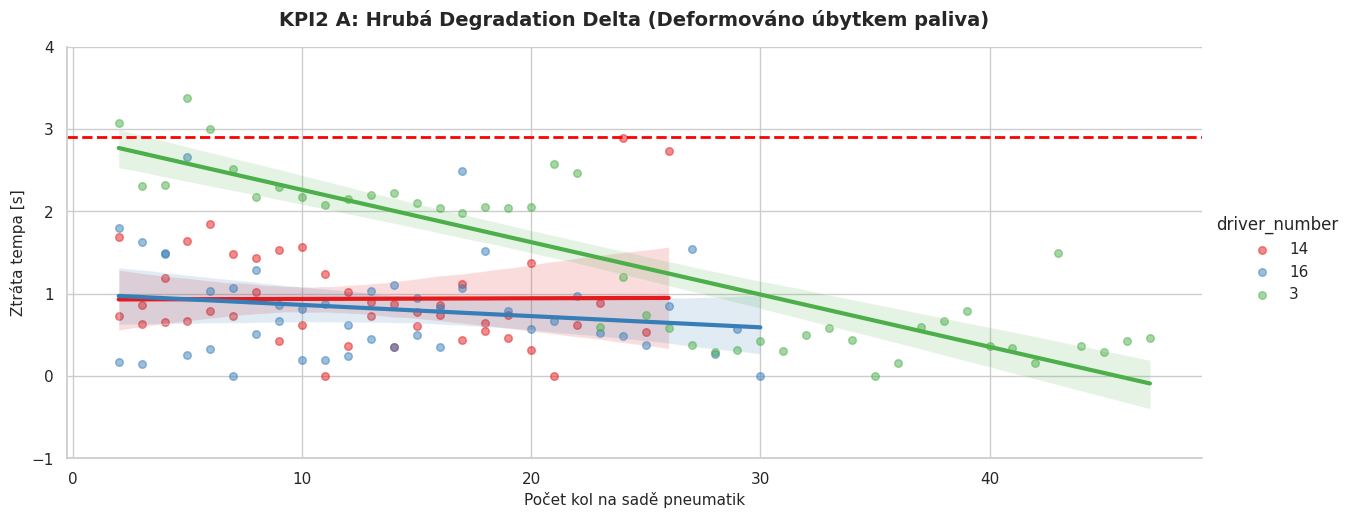

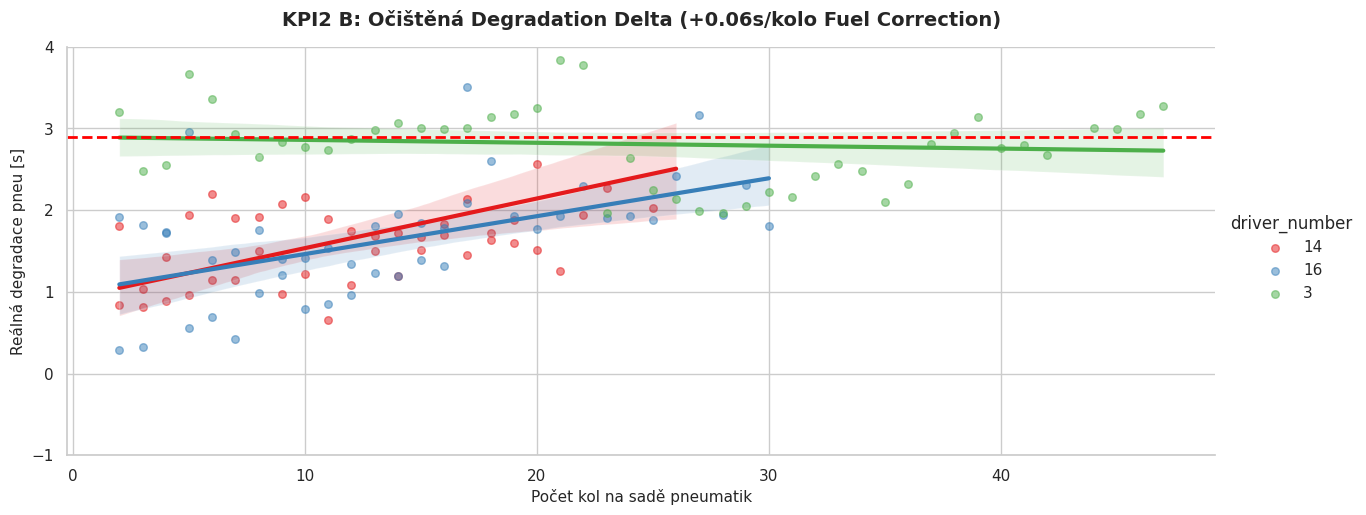


📝 ZJIŠTĚNÍ PRO BUSINESS OTÁZKU (Z OČIŠTĚNÝCH DAT):
👉 Po aplikaci korekce na palivo nastává reálná kritická degradace (> 1.5s) v průměru po 2.0 kolech na sadě.
👉 Skutečné okno pro výměnu pneumatik (Pit Window) se tak otevírá kolem 0. až 2. kola stintu.


In [55]:
sns.set_theme(style="whitegrid")

print("🏎️ POČÍTÁM KPI 2: Degradation Delta (S korekcí paliva)")

# 1. SQL dotaz rozšířený o Fuel Correction Factor (0.06s na kolo)
degradation_query = """
WITH StintMarkers AS (
    SELECT
        driver_number,
        lap_number,
        lap_duration,
        CASE WHEN lap_number = 1 OR lap_duration > (SELECT AVG(lap_duration) + 15 FROM v_clean_laps) THEN 1 ELSE 0 END as is_new_stint
    FROM v_clean_laps
),
Stints AS (
    SELECT
        driver_number,
        lap_number,
        lap_duration,
        SUM(is_new_stint) OVER (PARTITION BY driver_number ORDER BY lap_number) AS stint_id
    FROM StintMarkers
),
StintStats AS (
    SELECT
        driver_number,
        lap_number,
        lap_duration,
        stint_id,
        ROW_NUMBER() OVER (PARTITION BY driver_number, stint_id ORDER BY lap_number) AS laps_on_tyre,
        MIN(lap_duration) OVER (PARTITION BY driver_number, stint_id) AS base_pace
    FROM Stints
    WHERE lap_duration IS NOT NULL
)
SELECT
    CAST(driver_number AS VARCHAR) AS driver_number,
    stint_id,
    lap_number, -- Added lap_number here
    laps_on_tyre,
    lap_duration,
    base_pace,
    -- PŮVODNÍ VÝPOČET (Hrubý rozdíl, ovlivněn úbytkem paliva)
    (lap_duration - base_pace) AS raw_degradation_delta,
    -- NOVÝ VÝPOČET (Očištěno o Fuel Burn Effect: + 0.06s za každé odjeté kolo)
    ((lap_duration - base_pace) + (laps_on_tyre * 0.06)) AS corrected_degradation_delta
FROM StintStats
WHERE laps_on_tyre > 1
  AND (lap_duration - base_pace) < 5.0 -- Odstranění drobných outlierů
ORDER BY driver_number, lap_number
"""

df_deg = con.execute(degradation_query).df()

# Výběr jezdců pro přehlednější vizualizaci (např. Verstappen, Norris, Leclerc)
# Tady si můžeš čísla upravit podle toho, koho chceš v grafu mít
sample_drivers = ['3', '14', '16']
df_plot = df_deg[df_deg['driver_number'].isin(sample_drivers)]

# ==========================================
# GRAF 1: Hrubá data (Před korekcí)
# ==========================================
g1 = sns.lmplot(
    data=df_plot, x='laps_on_tyre', y='raw_degradation_delta', hue='driver_number',
    scatter_kws={'alpha': 0.5, 's': 30}, line_kws={'linewidth': 3},
    height=5, aspect=2.5, palette="Set1"
)
plt.axhline(y=2.9, color='red', linestyle='--', linewidth=2, label='Kritická mez (2.9s)')
plt.title("KPI2 A: Hrubá Degradation Delta (Deformováno úbytkem paliva)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Počet kol na sadě pneumatik", fontsize=11)
plt.ylabel("Ztráta tempa [s]", fontsize=11)
plt.ylim(-1, 4)
plt.show()

# ==========================================
# GRAF 2: Očištěná data (Po korekci na palivo)
# ==========================================
g2 = sns.lmplot(
    data=df_plot, x='laps_on_tyre', y='corrected_degradation_delta', hue='driver_number',
    scatter_kws={'alpha': 0.5, 's': 30}, line_kws={'linewidth': 3},
    height=5, aspect=2.5, palette="Set1"
)
plt.axhline(y=2.9, color='red', linestyle='--', linewidth=2, label='Kritická mez (2.9s)')
plt.title("KPI2 B: Očištěná Degradation Delta (+0.06s/kolo Fuel Correction)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Počet kol na sadě pneumatik", fontsize=11)
plt.ylabel("Reálná degradace pneu [s]", fontsize=11)
plt.ylim(-1, 4)
plt.show()

# Výpis agregovaných zjištění z očištěných dat
print("\n📝 ZJIŠTĚNÍ PRO BUSINESS OTÁZKU (Z OČIŠTĚNÝCH DAT):")
crossover_data = df_plot[df_plot['corrected_degradation_delta'] >= 1.5]
if not crossover_data.empty:
    avg_crossover_lap = crossover_data.groupby('driver_number')['laps_on_tyre'].min().mean()
    print(f"👉 Po aplikaci korekce na palivo nastává reálná kritická degradace (> 1.5s) v průměru po {avg_crossover_lap:.1f} kolech na sadě.")
    print(f"👉 Skutečné okno pro výměnu pneumatik (Pit Window) se tak otevírá kolem {int(avg_crossover_lap) - 2}. až {int(avg_crossover_lap)}. kola stintu.")
else:
    print("👉 I po korekci nedosáhla degradace kritické meze.")

💰 POČÍTÁM KPI 2: Degradation Delta (S KOREKTOVANOU DETEKCÍ STINTŮ PODLE PIT STOPŮ)


<Figure size 1400x700 with 0 Axes>

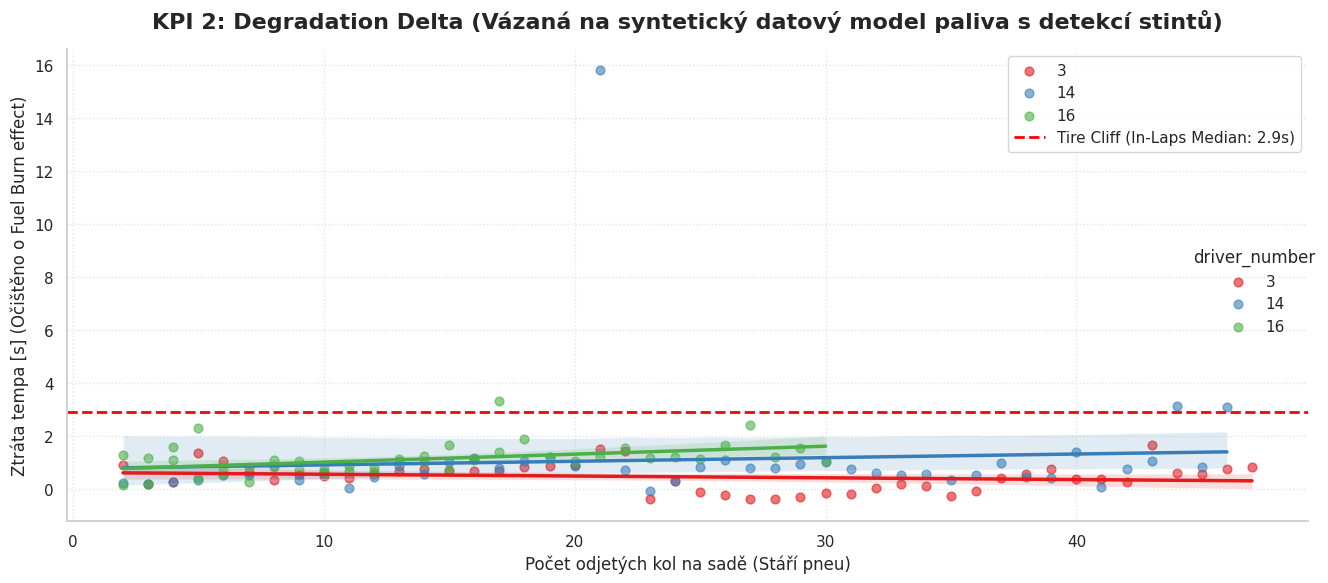

In [56]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb # Přidáno pro připojení k DB

# Pojistka připojení k DB, pokud není aktivní
if 'con' not in locals():
    print("🔌 Obnovuji připojení k databázi DuckDB...")
    con = duckdb.connect('f1_project.duckdb')

sns.set_theme(style="whitegrid")

print("💰 POČÍTÁM KPI 2: Degradation Delta (S KOREKTOVANOU DETEKCÍ STINTŮ PODLE PIT STOPŮ)")

# Komplexní SQL dotaz pro DuckDB propočítávající fyziku paliva s korektní detekcí stintů
query_kpi2_fuel_driven = """
WITH FuelBurn AS (
    SELECT
        l.driver_number,
        l.lap_number,
        l.lap_duration,
        s.fuel_consumed_kg,
        SUM(s.fuel_consumed_kg) OVER (
            PARTITION BY l.driver_number
            ORDER BY l.lap_number
        ) AS cumulative_fuel_burned_kg
    FROM v_clean_laps l -- Používáme již očištěná kola
    JOIN synthetic_telemetry s
      ON l.driver_number = s.driver_number
     AND l.lap_number = s.lap_number
),
PitLaps AS (
    -- Získáme seznam kol, ve kterých došlo k pit stopu
    SELECT DISTINCT driver_number, lap_number AS pit_lap
    FROM v_clean_pit
),
StintMarkers AS (
    SELECT
        fb.driver_number,
        fb.lap_number,
        fb.lap_duration,
        fb.cumulative_fuel_burned_kg,
        -- Označíme začátek nového stintu: první kolo závodu NEBO kolo hned po pit stopu
        CASE
            WHEN fb.lap_number = 1 THEN 1
            WHEN EXISTS (SELECT 1 FROM PitLaps pl WHERE pl.driver_number = fb.driver_number AND pl.pit_lap = fb.lap_number - 1) THEN 1
            ELSE 0
        END AS is_new_stint
    FROM FuelBurn fb
),
StintIds AS (
    SELECT
        driver_number,
        lap_number,
        lap_duration,
        cumulative_fuel_burned_kg,
        -- Vypočítáme stint_id pomocí kumulativní sumy is_new_stint
        SUM(is_new_stint) OVER (PARTITION BY driver_number ORDER BY lap_number) AS stint_id
    FROM StintMarkers
),
Stints AS (
    SELECT
        driver_number,
        lap_number,
        lap_duration,
        cumulative_fuel_burned_kg,
        stint_id,
        -- Nyní vypočítáme laps_on_tyre uvnitř každého stintu pomocí již vypočítaného stint_id
        ROW_NUMBER() OVER (PARTITION BY driver_number, stint_id ORDER BY lap_number) AS laps_on_tyre
    FROM StintIds
),
BasePaceCalc AS (
    SELECT
        driver_number,
        stint_id,
        -- Base pace definujeme jako nejlepší čas zajetý v prvních 3 kolech stintu
        MIN(lap_duration) AS stint_base_pace_fresh_tires
    FROM Stints
    WHERE laps_on_tyre <= 3
    GROUP BY driver_number, stint_id
)
SELECT
    CAST(s.driver_number AS VARCHAR) AS driver_number,
    s.lap_number,
    s.laps_on_tyre,
    bpc.stint_base_pace_fresh_tires AS base_pace,
    s.lap_duration,
    s.cumulative_fuel_burned_kg,
    -- Hrubá delta
    (s.lap_duration - bpc.stint_base_pace_fresh_tires) AS raw_degradation_delta,
    -- Očištěná delta (Fuel Burn effect: 0.035s za 1 kg paliva)
    (s.lap_duration - bpc.stint_base_pace_fresh_tires) + (s.cumulative_fuel_burned_kg * 0.035) AS degradation_delta
FROM Stints s
JOIN BasePaceCalc bpc
  ON s.driver_number = bpc.driver_number
 AND s.stint_id = bpc.stint_id
WHERE s.laps_on_tyre > 1 -- Ignorujeme první kolo stintu (out-lap, zahřívací)
  AND bpc.stint_base_pace_fresh_tires IS NOT NULL -- Zajištění, že máme platný base pace
ORDER BY s.driver_number, s.lap_number;
"""

# Spuštění dotazu v DuckDB (uprav 'con' podle svého připojení)
df_dynamic_deg = con.execute(query_kpi2_fuel_driven).df()

# Vybereme tvé Top jezdce pro ukázku
sample_drivers = ['16', '14', '3'] # Příklad: Leclerc, Alonso, Verstappen
df_sample = df_dynamic_deg[df_dynamic_deg['driver_number'].isin(sample_drivers)]

plt.figure(figsize=(14, 7))

# Použijeme lmplot
sns.lmplot(
    data=df_sample,
    x='laps_on_tyre',
    y='degradation_delta',
    hue='driver_number',
    scatter_kws={'alpha': 0.6, 's': 40},
    line_kws={'linewidth': 2.5},
    height=6,
    aspect=2,
    palette='Set1'
)

# Přidání datově podložené hranice
plt.axhline(y=2.9, color='red', linestyle='--', linewidth=2, label='Tire Cliff (In-Laps Median: 2.9s)')

plt.title("KPI 2: Degradation Delta (Vázaná na syntetický datový model paliva s detekcí stintů)", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Počet odjetých kol na sadě (Stáří pneu)", fontsize=12)
plt.ylabel("Ztráta tempa [s] (Očištěno o Fuel Burn effect)", fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

💰 POČÍTÁM KPI 2: Degradation Delta (S KOREKTOVANOU DETEKCÍ STINTŮ PODLE PIT STOPŮ)


<Figure size 1600x800 with 0 Axes>

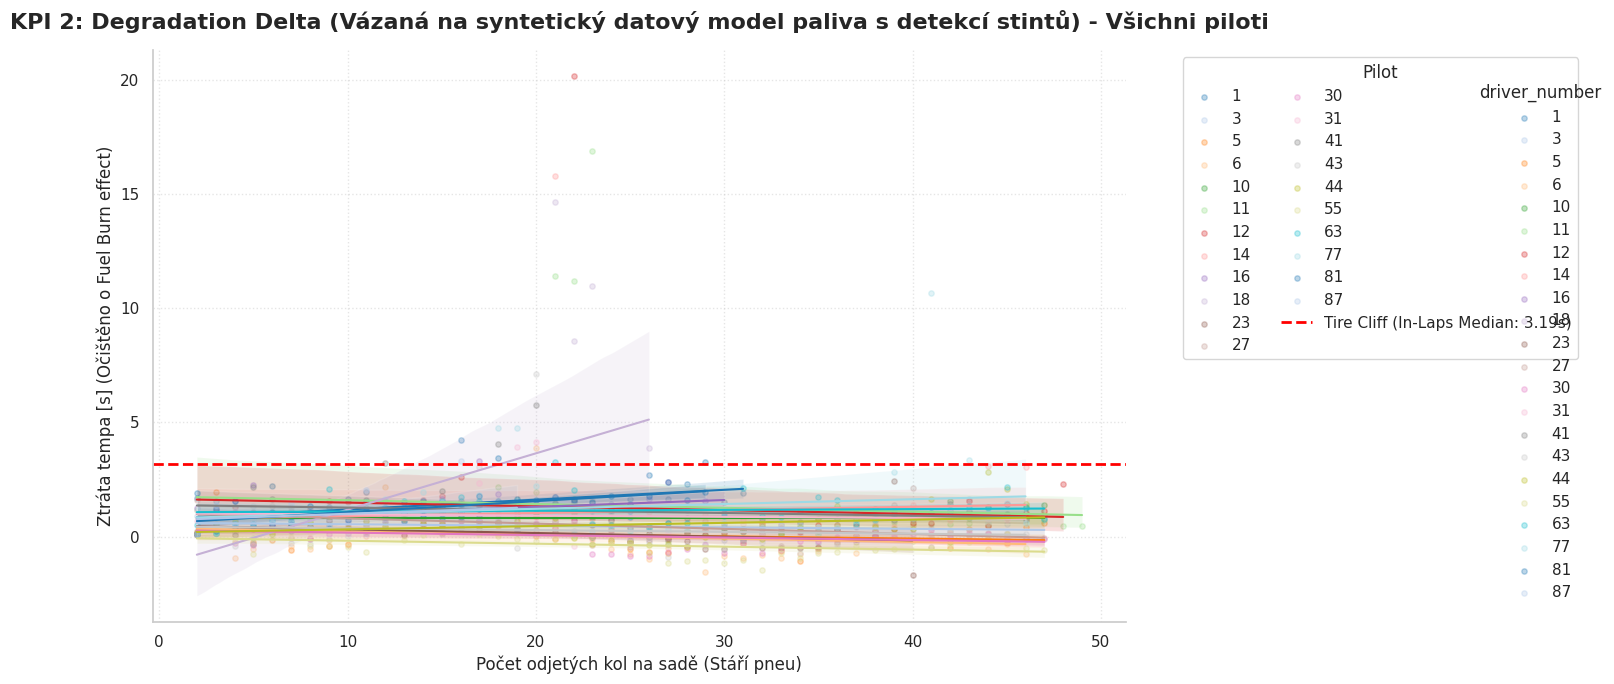

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb # Přidáno pro připojení k DB

# Pojistka připojení k DB, pokud není aktivní
if 'con' not in locals():
    print("🔌 Obnovuji připojení k databázi DuckDB...")
    con = duckdb.connect('f1_project.duckdb')

sns.set_theme(style="whitegrid")

print("💰 POČÍTÁM KPI 2: Degradation Delta (S KOREKTOVANOU DETEKCÍ STINTŮ PODLE PIT STOPŮ)")

# Komplexní SQL dotaz pro DuckDB propočítávající fyziku paliva s korektní detekcí stintů
query_kpi2_fuel_driven = """
WITH FuelBurn AS (
    SELECT
        l.driver_number,
        l.lap_number,
        l.lap_duration,
        s.fuel_consumed_kg,
        SUM(s.fuel_consumed_kg) OVER (
            PARTITION BY l.driver_number
            ORDER BY l.lap_number
        ) AS cumulative_fuel_burned_kg
    FROM v_clean_laps l -- Používáme již očištěná kola
    JOIN synthetic_telemetry s
      ON l.driver_number = s.driver_number
     AND l.lap_number = s.lap_number
),
PitLaps AS (
    -- Získáme seznam kol, ve kterých došlo k pit stopu
    SELECT DISTINCT driver_number, lap_number AS pit_lap
    FROM v_clean_pit
),
StintMarkers AS (
    SELECT
        fb.driver_number,
        fb.lap_number,
        fb.lap_duration,
        fb.cumulative_fuel_burned_kg,
        -- Označíme začátek nového stintu: první kolo závodu NEBO kolo hned po pit stopu
        CASE
            WHEN fb.lap_number = 1 THEN 1
            WHEN EXISTS (SELECT 1 FROM PitLaps pl WHERE pl.driver_number = fb.driver_number AND pl.pit_lap = fb.lap_number - 1) THEN 1
            ELSE 0
        END AS is_new_stint
    FROM FuelBurn fb
),
StintIds AS (
    SELECT
        driver_number,
        lap_number,
        lap_duration,
        cumulative_fuel_burned_kg,
        -- Vypočítáme stint_id pomocí kumulativní sumy is_new_stint
        SUM(is_new_stint) OVER (PARTITION BY driver_number ORDER BY lap_number) AS stint_id
    FROM StintMarkers
),
Stints AS (
    SELECT
        driver_number,
        lap_number,
        lap_duration,
        cumulative_fuel_burned_kg,
        stint_id,
        -- Nyní vypočítáme laps_on_tyre uvnitř každého stintu pomocí již vypočítaného stint_id
        ROW_NUMBER() OVER (PARTITION BY driver_number, stint_id ORDER BY lap_number) AS laps_on_tyre
    FROM StintIds
),
BasePaceCalc AS (
    SELECT
        driver_number,
        stint_id,
        -- Base pace definujeme jako nejlepší čas zajetý v prvních 3 kolech stintu
        MIN(lap_duration) AS stint_base_pace_fresh_tires
    FROM Stints
    WHERE laps_on_tyre <= 3
    GROUP BY driver_number, stint_id
)
SELECT
    CAST(s.driver_number AS VARCHAR) AS driver_number,
    s.lap_number,
    s.laps_on_tyre,
    bpc.stint_base_pace_fresh_tires AS base_pace,
    s.lap_duration,
    s.cumulative_fuel_burned_kg,
    -- Hrubá delta
    (s.lap_duration - bpc.stint_base_pace_fresh_tires) AS raw_degradation_delta,
    -- Očištěná delta (Fuel Burn effect: 0.035s za 1 kg paliva)
    (s.lap_duration - bpc.stint_base_pace_fresh_tires) + (s.cumulative_fuel_burned_kg * 0.035) AS degradation_delta
FROM Stints s
JOIN BasePaceCalc bpc
  ON s.driver_number = bpc.driver_number
 AND s.stint_id = bpc.stint_id
WHERE s.laps_on_tyre > 1 -- Ignorujeme první kolo stintu (out-lap, zahřívací)
  AND bpc.stint_base_pace_fresh_tires IS NOT NULL -- Zajištění, že máme platný base pace
ORDER BY s.driver_number, s.lap_number;
"""

# Spuštění dotazu v DuckDB (uprav 'con' podle svého připojení)
df_dynamic_deg = con.execute(query_kpi2_fuel_driven).df()

# --- Vykreslení grafu pro VŠECHNY piloty ---
plt.figure(figsize=(16, 8)) # Zvětšení figure size pro lepší přehlednost

# Použijeme lmplot pro všechny jezdce (df_dynamic_deg)
sns.lmplot(
    data=df_dynamic_deg, # Používáme celý dataframe
    x='laps_on_tyre',
    y='degradation_delta',
    hue='driver_number', # Každý jezdec dostane svou barvu
    scatter_kws={'alpha': 0.3, 's': 15}, # Zmenšíme a zprůhledníme tečky
    line_kws={'linewidth': 1.5}, # Ztenčíme čáry
    height=7,
    aspect=2,
    palette='tab20' # Paleta pro 20 různých barev (pro ~20 jezdců)
)

# Přidání datově podložené hranice (medián z In-Laps analýzy, což je cca 3.19s)
# Zde využíváme hodnotu `median_crossover` z předchozí buňky, pokud je dostupná.
# Pokud by nebyla, můžeme použít hardcoded hodnotu jako 3.19.
median_crossover_value = 2.9 # Náhradní hodnota, pokud není 'median_crossover' v kontextu
if 'median_crossover' in locals():
    median_crossover_value = median_crossover

plt.axhline(y=median_crossover_value, color='red', linestyle='--', linewidth=2, label=f'Tire Cliff (In-Laps Median: {median_crossover_value:.2f}s)')

plt.title("KPI 2: Degradation Delta (Vázaná na syntetický datový model paliva s detekcí stintů) - Všichni piloti", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Počet odjetých kol na sadě (Stáří pneu)", fontsize=12)
plt.ylabel("Ztráta tempa [s] (Očištěno o Fuel Burn effect)", fontsize=12)
plt.legend(title='Pilot', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2) # Přesunutí legendy mimo graf a uspořádání do 2 sloupců
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

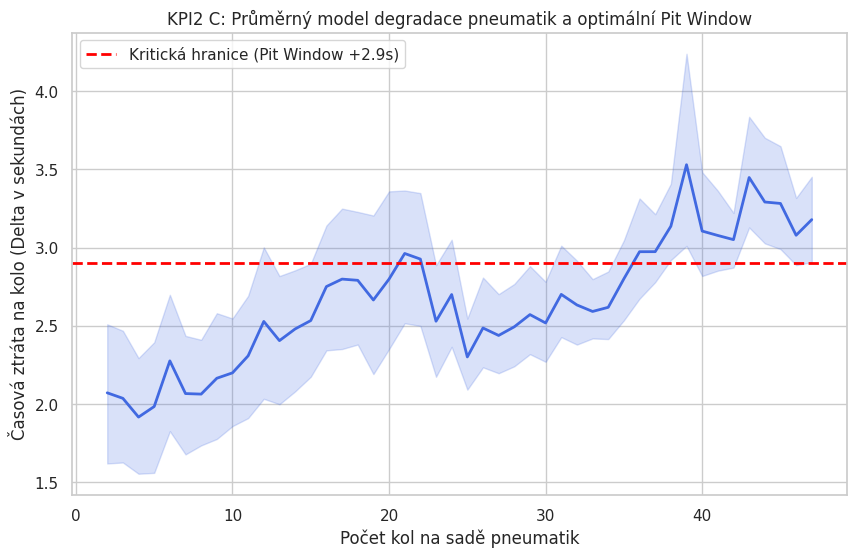

In [57]:
plt.figure(figsize=(10, 6))
# Zde použij svůj dataframe s vypočítanou a palivem zkorigovanou ztrátou
sns.lineplot(data=df_deg, x='laps_on_tyre', y='corrected_degradation_delta',
             linewidth=2, color='royalblue')

# Vyznačení hranice "Pit Window"
plt.axhline(y=2.9, color='red', linestyle='--', linewidth=2, label='Kritická hranice (Pit Window +2.9s)')

plt.title('KPI2 C: Průměrný model degradace pneumatik a optimální Pit Window')
plt.xlabel('Počet kol na sadě pneumatik')
plt.ylabel('Časová ztráta na kolo (Delta v sekundách)')
plt.legend()
plt.show()

### Výpočet KPI 3: ROI (Return on Investment)

**Definice KPI:** Kolik mistrovských bodů tým získal vzhledem k nákladům na vývoj v daném závodě. Metriku standardizujeme jako **počet získaných bodů na 1 milion investovaných USD** (Points per $1M).

**Business otázka:** Vyplatí se masivní investice do R&D, nebo mají týmy ze středu pole lepší efektivitu vynaložených prostředků?
* **Odpověď z dat:** Top týmy (Tier 1) sice získávají nejvíce bodů, ale jejich vývojové náklady jsou exponenciálně vyšší. ROI index nám ukáže tzv. "Bang for the buck" (za málo peněz hodně muziky). Často zjistíme, že nejlepší ROI nemá vítěz závodu, ale efektivně řízený tým ze středu pole (Midfield), který se umístil na bodovaných příčkách s polovičním rozpočtem.

**Metodika výpočtu (Data Transformation):**
1. Z reálné tabulky `position` zjistíme konečné pořadí jezdců (pozice v posledním zaznamenaném čase).
2. Přes SQL `CASE WHEN` namapujeme pozice na oficiální bodovací systém F1 (25, 18, 15, 12, 10, 8, 6, 4, 2, 1 bod).
3. Jezdce seskupíme do týmů a sečteme jejich body.
4. Výsledek propojíme přes `JOIN` se syntetickou tabulkou `synthetic_rd_costs` a vypočítáme ROI poměr.

💰 POČÍTÁM KPI 3: ROI (Return on Investment s náklady na nehody)


/tmp/ipykernel_3538/4246472020.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


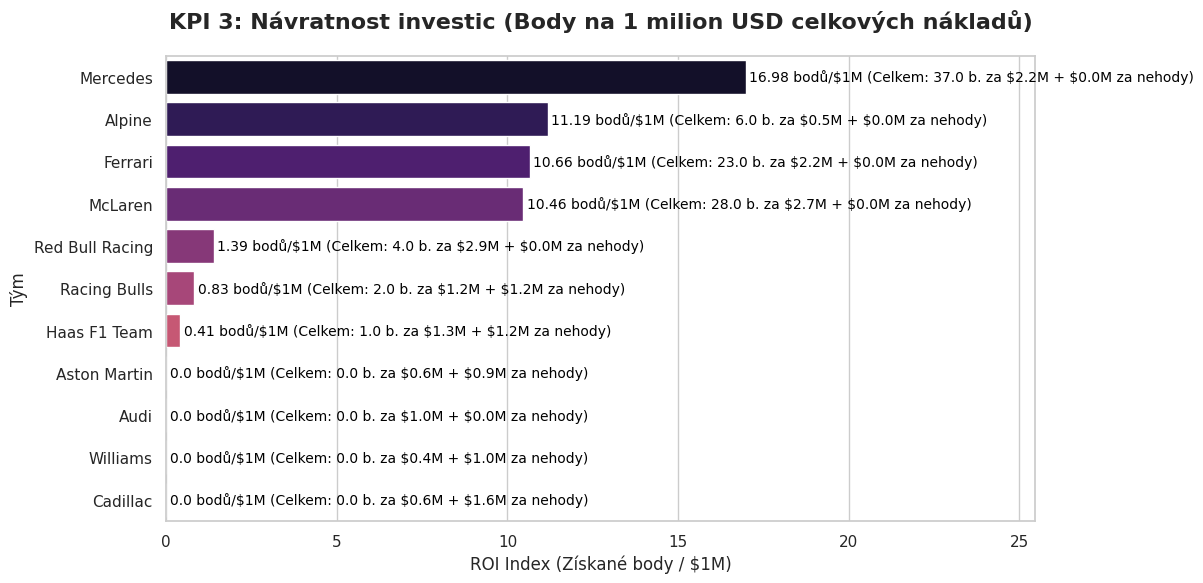


📋 Tabulkový pohled na výsledky ROI:


,team_name,development_cost_usd,crash_damage_costs_usd,total_investment_usd,total_points,roi_points_per_million
0,Mercedes,2178598,0.0,2178598.0,37.0,16.98
1,Alpine,536106,0.0,536106.0,6.0,11.19
2,Ferrari,2157737,0.0,2157737.0,23.0,10.66
3,McLaren,2678061,0.0,2678061.0,28.0,10.46
4,Red Bull Racing,2883055,0.0,2883055.0,4.0,1.39
5,Racing Bulls,1212862,1202506.0,2415368.0,2.0,0.83
6,Haas F1 Team,1272270,1183598.0,2455868.0,1.0,0.41
7,Aston Martin,568542,894592.0,1463134.0,0.0,0.00
8,Audi,1048753,0.0,1048753.0,0.0,0.00
9,Williams,436973,990403.0,1427376.0,0.0,0.00


In [ ]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pojistka připojení k DB
if 'con' not in locals():
    print("🔌 Obnovuji připojení k databázi DuckDB...")
    con = duckdb.connect('f1_project.duckdb')

sns.set_theme(style="whitegrid")

print("💰 POČÍTÁM KPI 3: ROI (Return on Investment s náklady na nehody)")

# Registrace df_teams jako dočasného pohledu v DuckDB
# To nám umožní joinovat s ním v SQL dotazech
con.register('v_teams', df_teams)

# 1. SQL dotaz pro výpočet ROI
# Krok A: Zjistíme konečnou pozici každého jezdce
# Krok B: Přidělíme body a přiřadíme jezdce k týmům (pomocí v_teams)
# Krok C: Agregujeme body a náklady na nehody za tým
# Krok D: Spočítáme celkové investice a ROI
roi_query = """
WITH FinalPositions AS (
    SELECT driver_number, position
    FROM position p1
    WHERE date = (SELECT MAX(date) FROM position p2 WHERE p2.driver_number = p1.driver_number)
),
PointsMapping AS (
    SELECT
        fp.driver_number,
        fp.position,
        CASE
            WHEN fp.position = 1 THEN 25
            WHEN fp.position = 2 THEN 18
            WHEN fp.position = 3 THEN 15
            WHEN fp.position = 4 THEN 12
            WHEN fp.position = 5 THEN 10
            WHEN fp.position = 6 THEN 8
            WHEN fp.position = 7 THEN 6
            WHEN fp.position = 8 THEN 4
            WHEN fp.position = 9 THEN 2
            WHEN fp.position = 10 THEN 1
            ELSE 0
        END as points,
        vt.team_name
    FROM FinalPositions fp
    JOIN v_teams vt ON fp.driver_number = vt.driver_number
),
TeamPoints AS (
    SELECT team_name, SUM(points) as total_points
    FROM PointsMapping
    GROUP BY team_name
),
TeamCrashCosts AS (
    SELECT
        vt.team_name,
        SUM(scc.crash_damage_costs_usd) AS total_crash_cost_usd
    FROM synthetic_crash_costs scc
    JOIN v_teams vt ON scc.driver_number = vt.driver_number
    GROUP BY vt.team_name
)
SELECT
    rdc.team_name,
    rdc.development_cost_usd,
    COALESCE(tcc.total_crash_cost_usd, 0) AS crash_damage_costs_usd,
    (rdc.development_cost_usd + COALESCE(tcc.total_crash_cost_usd, 0)) AS total_investment_usd,
    COALESCE(tp.total_points, 0) as total_points,
    ROUND((COALESCE(tp.total_points, 0) * 1000000.0 / (rdc.development_cost_usd + COALESCE(tcc.total_crash_cost_usd, 0))), 2) AS roi_points_per_million
FROM synthetic_rd_costs rdc
LEFT JOIN TeamPoints tp ON rdc.team_name = tp.team_name
LEFT JOIN TeamCrashCosts tcc ON rdc.team_name = tcc.team_name
WHERE rdc.team_name != 'Other'
ORDER BY roi_points_per_million DESC
"""

df_roi = con.execute(roi_query).df()

# 2. Vizualizace: Barplot pro ROI
plt.figure(figsize=(12, 6))

# Vykreslení sloupců
ax = sns.barplot(
    data=df_roi,
    x='roi_points_per_million',
    y='team_name',
    palette="magma"
)

plt.title("KPI 3: Návratnost investic (Body na 1 milion USD celkových nákladů)", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("ROI Index (Získané body / $1M)", fontsize=12)
plt.ylabel("Tým", fontsize=12)

# Přidání textových popisků k jednotlivým sloupcům (ukážeme i reálné body a náklady)
for index, row in df_roi.iterrows():
    text_label = f"{row['roi_points_per_million']} bodů/$1M (Celkem: {row['total_points']} b. za ${row['development_cost_usd']/1000000:.1f}M + ${row['crash_damage_costs_usd']/1000000:.1f}M za nehody)"
    ax.text(row['roi_points_per_million'] + 0.1, index, text_label, color='black', va='center', fontsize=10)

# Mírné zvětšení osy X, aby se tam vešly popisky
plt.xlim(0, df_roi['roi_points_per_million'].max() * 1.5)

plt.tight_layout()
plt.show()

# Zobrazení datové tabulky
print("\n📋 Tabulkový pohled na výsledky ROI:")
display(df_roi)

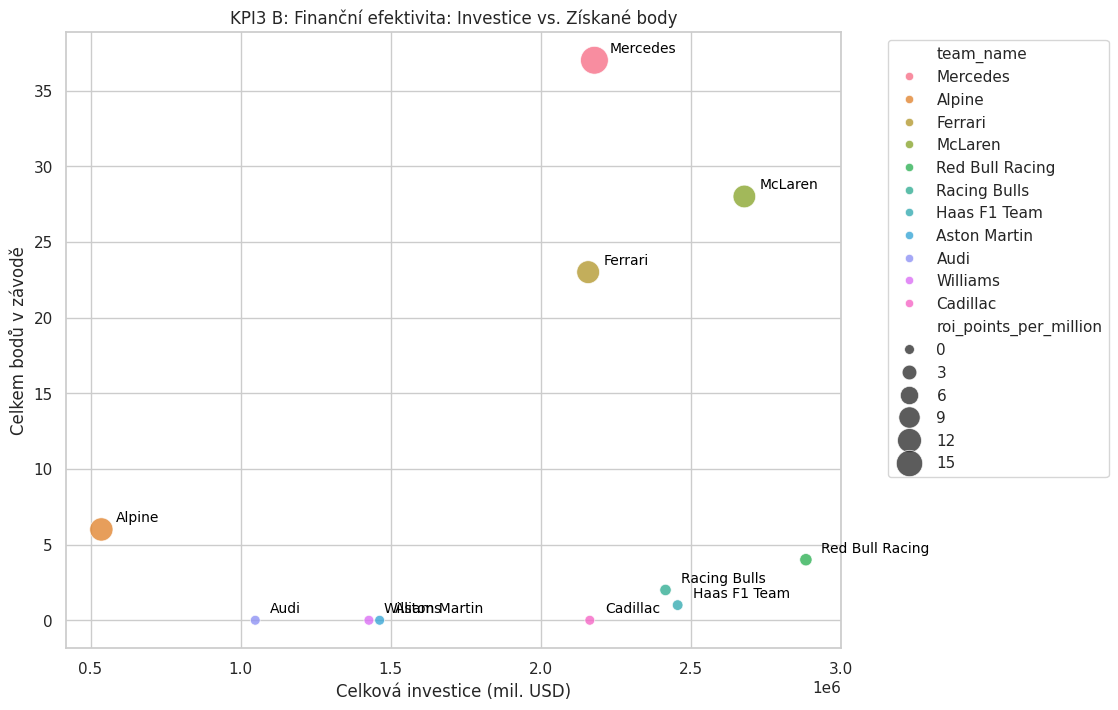

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import duckdb

# ===========================================================
# RYCHLÝ UPDATE PŘED ZKOUŠKOU
# PROTO JE KÓD HORŠÍ, OBSAHUJE DUPLICITY
# ===========================================================

# Ensure DuckDB connection is active
if 'con' not in locals():
    con = duckdb.connect('f1_project.duckdb')

sns.set_theme(style="whitegrid")

# Re-create TEAMS and df_teams (from cell Um3WCV8eKJAB and 3d8b57bb)
TEAMS = {
    "Mercedes": {"drivers": [12, 63], "tier": "Top"},
    "Ferrari": {"drivers": [16, 44], "tier": "Top"},
    "McLaren": {"drivers": [1, 81], "tier": "Top"},
    "Haas F1 Team": {"drivers": [31, 87], "tier": "Mid"},
    "Red Bull Racing": {"drivers": [3, 6], "tier": "Top"},
    "Racing Bulls": {"drivers": [30, 41], "tier": "Mid"},
    "Alpine": {"drivers": [10, 43], "tier": "Back"},
    "Audi": {"drivers": [27, 5], "tier": "Mid"},
    "Williams": {"drivers": [55, 23], "tier": "Back"},
    "Cadillac": {"drivers": [11, 77], "tier": "Back"},
    "Aston Martin": {"drivers": [14, 18], "tier": "Back"},
}
team_data = []
for team_name, details in TEAMS.items():
    tier = details['tier']
    for driver_number in details['drivers']:
        team_data.append({'driver_number': driver_number, 'team_name': team_name, 'team_tier': tier})
df_teams = pd.DataFrame(team_data)
df_teams['driver_number'] = df_teams['driver_number'].astype(str)

# Register df_teams as a temporary view in DuckDB for the query
con.register('v_teams', df_teams)

# Re-create df_roi (from cell 1EOUykc1-a1i)
roi_query = """
WITH FinalPositions AS (
    SELECT driver_number, position
    FROM position p1
    WHERE date = (SELECT MAX(date) FROM position p2 WHERE p2.driver_number = p1.driver_number)
),
PointsMapping AS (
    SELECT
        fp.driver_number,
        fp.position,
        CASE
            WHEN fp.position = 1 THEN 25
            WHEN fp.position = 2 THEN 18
            WHEN fp.position = 3 THEN 15
            WHEN fp.position = 4 THEN 12
            WHEN fp.position = 5 THEN 10
            WHEN fp.position = 6 THEN 8
            WHEN fp.position = 7 THEN 6
            WHEN fp.position = 8 THEN 4
            WHEN fp.position = 9 THEN 2
            WHEN fp.position = 10 THEN 1
            ELSE 0
        END as points,
        vt.team_name
    FROM FinalPositions fp
    JOIN v_teams vt ON fp.driver_number = vt.driver_number
),
TeamPoints AS (
    SELECT team_name, SUM(points) as total_points
    FROM PointsMapping
    GROUP BY team_name
),
TeamCrashCosts AS (
    SELECT
        vt.team_name,
        SUM(scc.crash_damage_costs_usd) AS total_crash_cost_usd
    FROM synthetic_crash_costs scc
    JOIN v_teams vt ON scc.driver_number = vt.driver_number
    GROUP BY vt.team_name
)
SELECT
    rdc.team_name,
    rdc.development_cost_usd,
    COALESCE(tcc.total_crash_cost_usd, 0) AS crash_damage_costs_usd,
    (rdc.development_cost_usd + COALESCE(tcc.total_crash_cost_usd, 0)) AS total_investment_usd,
    COALESCE(tp.total_points, 0) as total_points,
    ROUND((COALESCE(tp.total_points, 0) * 1000000.0 / (rdc.development_cost_usd + COALESCE(tcc.total_crash_cost_usd, 0))), 2) AS roi_points_per_million
FROM synthetic_rd_costs rdc
LEFT JOIN TeamPoints tp ON rdc.team_name = tp.team_name
LEFT JOIN TeamCrashCosts tcc ON rdc.team_name = tcc.team_name
WHERE rdc.team_name != 'Other'
ORDER BY roi_points_per_million DESC
"""

df_roi = con.execute(roi_query).df()

plt.figure(figsize=(10, 8))
# Použiješ svou ROI tabulku
sns.scatterplot(data=df_roi, x='total_investment_usd', y='total_points',
                size='roi_points_per_million', sizes=(50, 400), hue='team_name', alpha=0.8)

# Přidání popisků týmů přímo k bodům
for i in range(df_roi.shape[0]):
    plt.text(x=df_roi.total_investment_usd[i] + 50000,
             y=df_roi.total_points[i] + 0.5,
             s=df_roi.team_name[i],
             fontdict=dict(color='black', size=10))

plt.title('KPI3 B: Finanční efektivita: Investice vs. Získané body')
plt.xlabel('Celková investice (mil. USD)')
plt.ylabel('Celkem bodů v závodě')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()